Problem Statement:

“Analyzing complex mutual fund data to understand fund performance, risk, investment trends, and investor behavior.”

Mutual fund investors have many investment options, but understanding and comparing funds based on performance, risk, NAV, AUM, SIP trends, and portfolio holdings can be difficult. The problem is to analyze this large and diverse mutual fund data and extract meaningful information that can help in understanding fund performance, investment trends, and investor behavior.

To solve this problem, I collected multiple mutual fund datasets containing information about fund categories, NAV, AUM, SIP inflows, scheme performance, investor transactions, and portfolio holdings. I implemented Exploratory Data Analysis using Python, Pandas, NumPy, and Matplotlib. I checked missing values and duplicates, performed statistical analysis, analyzed different categories and trends, and created visualizations. From this analysis, I identified useful insights such as Equity funds being the most common, Moderate risk being the most common risk level, positive SIP growth, and higher transaction activity among investors aged 26–35

Data Collection → Data Cleaning → EDA → Statistical Analysis → Visualization → Insights

1.Fund Master: Used to understand the basic details of mutual fund schemes, such as category, risk level, expense ratio, benchmark, and minimum investment.

2.NAV History: Used to analyze how the NAV of mutual funds changes over time and understand their value trends.

3.AUM by Fund House: Used to understand how much investor money is managed by different fund houses.

4.Monthly SIP Inflows: Used to analyze SIP investment trends and year-on-year growth.

5.Category Inflows: Used to understand which mutual fund categories receive more investment.

6.Industry Folio Count: Used to analyze investor participation across Equity, Debt, Hybrid, and other categories.

7.Scheme Performance: Used to analyze fund returns, risk, Alpha, Beta, Sharpe Ratio, and other performance measures.

8.Investor Transactions: Used to understand investor behavior based on transaction type, age group, location, and other factors.

9.Portfolio Holdings: Used to understand where mutual funds invest their money, including different stocks, sectors, and their portfolio weights.

10.Benchmark Indices: Used to understand market benchmark movements and compare them with fund performance.

11.Live NAV Datasets: Used to analyze the NAV trends of selected mutual funds such as Axis, HDFC, ICICI, Kotak, Nippon, and SBI.1

## Dataset 1: Fund Master

This dataset contains the basic information of different mutual fund schemes, including fund house, scheme name, category, sub-category, plan type, launch date, benchmark, expense ratio, exit load, and minimum SIP amount.

It provides the main profile and characteristics of each mutual fund scheme.

In [153]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [154]:
df = pd.read_csv("data/01_fund_master.csv")
df.head()

,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,119551,SBI Mutual Fund,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,Regular,2006-02-14,NIFTY 100 TRI,1.54,1.0,500,1000,Sohini Andani,Moderate,EC01
1,119552,SBI Mutual Fund,SBI Bluechip Fund - Direct Plan - Growth,Equity,Large Cap,Direct,2013-01-01,NIFTY 100 TRI,0.66,1.0,500,1000,Sohini Andani,Moderate,EC01
2,119598,SBI Mutual Fund,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,Regular,2009-09-09,BSE 250 SmallCap TRI,1.43,1.0,500,1000,R. Srinivasan,Very High,EC03
3,119599,SBI Mutual Fund,SBI Small Cap Fund - Direct Plan - Growth,Equity,Small Cap,Direct,2013-01-01,BSE 250 SmallCap TRI,0.72,1.0,500,1000,R. Srinivasan,Very High,EC03
4,119120,SBI Mutual Fund,SBI Magnum Gilt Fund - Regular Plan - Growth,Debt,Gilt,Regular,2000-12-30,CRISIL Dynamic Gilt Index,0.77,0.0,500,1000,Dinesh Ahuja,Low,DC02


| Column                 |  work                                        |
| ---------------------- | ----------------------------------------------------- |
| **amfi_code**          | Unique ID of the mutual fund                          |
| **fund_house**         | Company that manages the fund                         |
| **scheme_name**        | Name of the mutual fund                               |
| **category**           | Type of fund – Equity or Debt                         |
| **sub_category**       | More specific type – Large Cap, Small Cap, Gilt, etc. |
| **plan**               | Regular or Direct plan                                |
| **launch_date**        | Date when the fund was started                        |
| **benchmark**          | Index used to compare fund performance                |
| **expense_ratio_pct**  | Cost charged for managing the fund                    |
| **exit_load_pct**      | Charge that may apply when money is withdrawn         |
| **min_sip_amount**     | Minimum amount required for SIP                       |
| **min_lumpsum_amount** | Minimum amount for one-time investment                |
| **fund_manager**       | Person who manages the fund                           |
| **risk_category**      | Risk level – Low, Moderate, High, etc.                |
| **sebi_category_code** | Code used for the fund category                       |


In [155]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [156]:
df.shape

(40, 15)

### Dataset Shape
The Fund Master dataset contains 40 rows and 15 columns.

In [157]:
df.columns

Index(['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category',
       'plan', 'launch_date', 'benchmark', 'expense_ratio_pct',
       'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager',
       'risk_category', 'sebi_category_code'],
      dtype='object')

In [158]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   amfi_code           40 non-null     int64  
 1   fund_house          40 non-null     object 
 2   scheme_name         40 non-null     object 
 3   category            40 non-null     object 
 4   sub_category        40 non-null     object 
 5   plan                40 non-null     object 
 6   launch_date         40 non-null     object 
 7   benchmark           40 non-null     object 
 8   expense_ratio_pct   40 non-null     float64
 9   exit_load_pct       40 non-null     float64
 10  min_sip_amount      40 non-null     int64  
 11  min_lumpsum_amount  40 non-null     int64  
 12  fund_manager        40 non-null     object 
 13  risk_category       40 non-null     object 
 14  sebi_category_code  40 non-null     object 
dtypes: float64(2), int64(3), object(10)
memory usage: 4.8+ KB


In [159]:
df.isnull().sum()

amfi_code             0
fund_house            0
scheme_name           0
category              0
sub_category          0
plan                  0
launch_date           0
benchmark             0
expense_ratio_pct     0
exit_load_pct         0
min_sip_amount        0
min_lumpsum_amount    0
fund_manager          0
risk_category         0
sebi_category_code    0
dtype: int64

### Missing Values

The dataset contains no missing values. All columns have complete information, so no missing value treatment is required.

In [160]:
df.duplicated().sum()

np.int64(0)

### Duplicate Records

The dataset contains no duplicate rows. This indicates that all records are unique.

In [161]:
df.describe()

,amfi_code,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount
count,40.000000,40.000000,40.000000,40.0,40.000000
mean,120247.000000,1.237000,0.812500,500.0,1277.500000
std,14534.998667,0.386584,0.387091,0.0,1082.847031
min,100016.000000,0.550000,0.000000,500.0,100.000000
25%,118632.750000,0.787500,1.000000,500.0,1000.000000
50%,119551.500000,1.425000,1.000000,500.0,1000.000000
75%,120842.250000,1.540000,1.000000,500.0,1000.000000
max,149324.000000,1.640000,1.000000,500.0,5000.000000


### Statistical Summary

This summary provides the basic statistical information of the numerical features, including count, mean, standard deviation, minimum, maximum, and quartile values.

In [162]:
df.describe(include="object")

,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,fund_manager,risk_category,sebi_category_code
count,40,40,40,40,40,40,40,40,40,40
unique,10,40,2,12,2,34,10,29,5,9
top,SBI Mutual Fund,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,Regular,2013-01-01,NIFTY 100 TRI,Sohini Andani,Moderate,EC01
freq,5,1,34,14,32,7,14,2,16,14


In [163]:
df["category"].value_counts()

category
Equity    34
Debt       6
Name: count, dtype: int64

### Fund Category Distribution

The dataset contains 34 Equity schemes and 6 Debt schemes. Equity funds form the majority of the schemes in the dataset.

In [164]:
df["risk_category"].value_counts()

risk_category
Moderate           16
High                8
Very High           6
Low                 6
Moderately High     4
Name: count, dtype: int64

### Risk Category Distribution

Most schemes fall under the Moderate risk category, followed by High and Very High risk categories. The dataset also contains Low and Moderately High risk schemes.

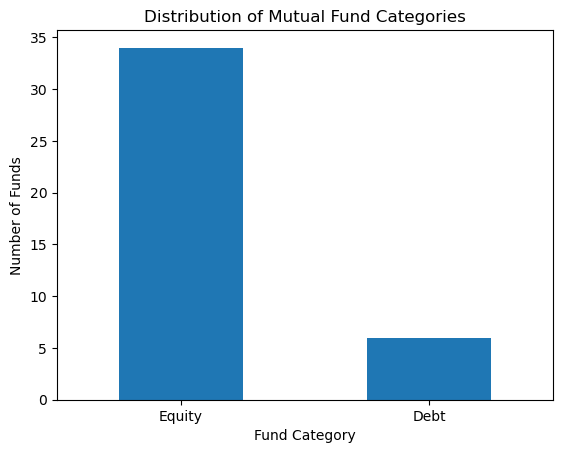

In [165]:
df["category"].value_counts().plot(kind="bar")

plt.title("Distribution of Mutual Fund Categories")
plt.xlabel("Fund Category")
plt.ylabel("Number of Funds")
plt.xticks(rotation=0)
plt.show()

### Observation

The graph shows that Equity funds dominate the dataset with 34 schemes, while only 6 schemes belong to the Debt category. This indicates that the dataset mainly focuses on Equity mutual funds.

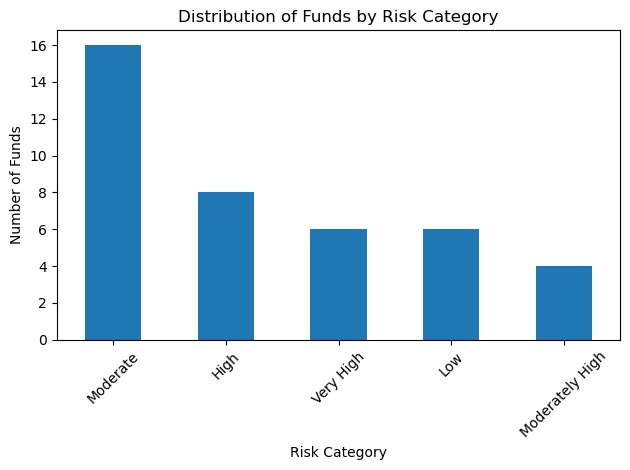

In [166]:
df["risk_category"].value_counts().plot(kind="bar")

plt.title("Distribution of Funds by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Funds")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

Most funds have Moderate risk. Some funds have High, Very High, Low, and Moderately High risk. Overall, Moderate risk funds are the most common in this dataset.

## Dataset 2: NAV History

This dataset contains the historical NAV values of different mutual fund schemes over time.

In [167]:
df2 = pd.read_csv("data/02_nav_history.csv")
df2.head()

,amfi_code,date,nav
0,119551,2022-01-03,54.3856
1,119551,2022-01-04,54.3474
2,119551,2022-01-05,54.6869
3,119551,2022-01-06,55.4550
4,119551,2022-01-07,55.3692


In [168]:
df2.shape

(46000, 3)

In [169]:
df2.columns

Index(['amfi_code', 'date', 'nav'], dtype='object')

In [170]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46000 entries, 0 to 45999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   amfi_code  46000 non-null  int64  
 1   date       46000 non-null  object 
 2   nav        46000 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 1.1+ MB


In [171]:
df2.isnull().sum()

amfi_code    0
date         0
nav          0
dtype: int64

In [172]:
df2.duplicated().sum()

np.int64(0)

In [173]:
df2.describe()

,amfi_code,nav
count,46000.000000,46000.000000
mean,120247.000000,269.570265
std,14352.317221,577.187060
min,100016.000000,26.136600
25%,118632.750000,69.170425
50%,119551.500000,122.732150
75%,120842.250000,260.338675
max,149324.000000,4268.549700


In [174]:
df2["amfi_code"].nunique()

40

In [175]:
df2["nav"].describe()

count    46000.000000
mean       269.570265
std        577.187060
min         26.136600
25%         69.170425
50%        122.732150
75%        260.338675
max       4268.549700
Name: nav, dtype: float64

In [176]:
df2["date"] = pd.to_datetime(df2["date"], dayfirst=True, errors="coerce")

df2.dtypes

amfi_code             int64
date         datetime64[ns]
nav                 float64
dtype: object

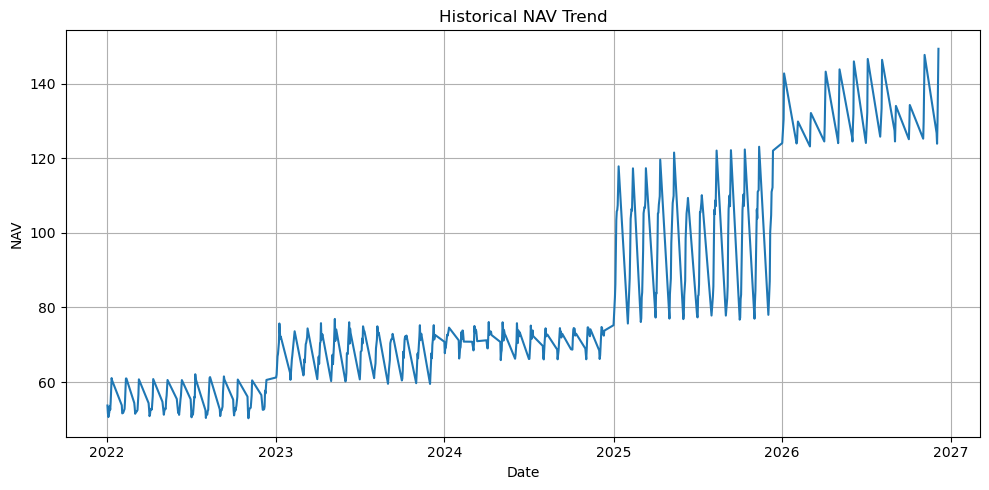

In [177]:
first_fund = df2["amfi_code"].iloc[0]

fund_data = df2[df2["amfi_code"] == first_fund].sort_values("date")

plt.figure(figsize=(10, 5))
plt.plot(fund_data["date"], fund_data["nav"])

plt.title("Historical NAV Trend")
plt.xlabel("Date")
plt.ylabel("NAV")
plt.grid(True)
plt.tight_layout()
plt.show()

### Insights 
* Short term : Nav value is frequently fluctuating 
* Long term : Its showing overall NAV upward trend

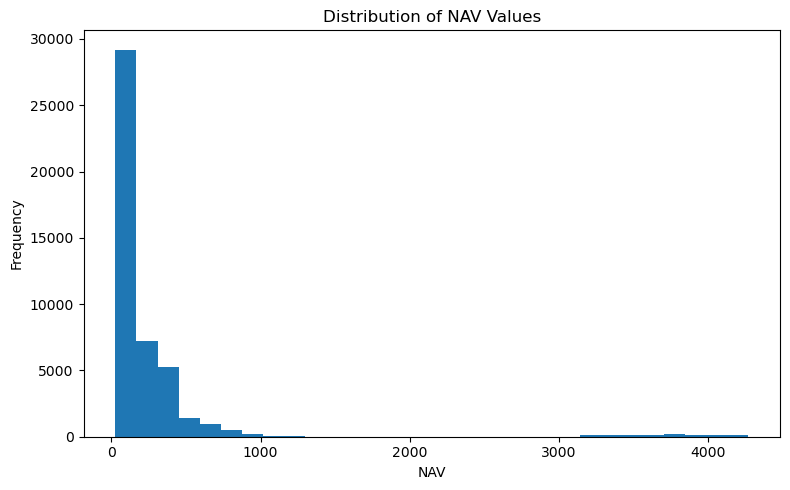

In [178]:
plt.figure(figsize=(8, 5))
plt.hist(df2["nav"].dropna(), bins=30)

plt.title("Distribution of NAV Values")
plt.xlabel("NAV")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Insights 
* Most NAV observations relatively low range - mostly concentrated .
* NAV distribution is highly right-skewed, with most observations concentrated at lower NAV values and a small number of very high NAV observations.

### Observation

The NAV history shows how mutual fund values change over time. The trend graph helps identify growth and fluctuations in a fund's NAV, while the distribution graph shows the overall range of NAV values present in the dataset.

In [179]:
print("Start Date:", df2["date"].min())
print("End Date:", df2["date"].max())

Start Date: 2022-01-02 00:00:00
End Date: 2026-12-05 00:00:00


## Dataset 3: AUM by Fund House

This dataset shows the Assets Under Management (AUM) of different mutual fund houses over time.

In [180]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df3 = pd.read_csv("data/03_aum_by_fund_house.csv")
df3.head()

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential MF,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195
3,2022-03-31,Nippon India MF,2.70,270000,177
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168


In [181]:
df3.shape

(90, 5)

In [182]:
df3.columns

Index(['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes'], dtype='object')

In [183]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            90 non-null     object 
 1   fund_house      90 non-null     object 
 2   aum_lakh_crore  90 non-null     float64
 3   aum_crore       90 non-null     int64  
 4   num_schemes     90 non-null     int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 3.6+ KB


In [184]:
df3.isnull().sum()

date              0
fund_house        0
aum_lakh_crore    0
aum_crore         0
num_schemes       0
dtype: int64

In [185]:
df3.duplicated().sum()

np.int64(0)

In [186]:
df3.describe()

,aum_lakh_crore,aum_crore,num_schemes
count,90.000000,9.000000e+01,90.000000
mean,4.352889,4.352889e+05,152.200000
std,2.734328,2.734328e+05,52.108832
min,1.050000,1.050000e+05,56.000000
25%,2.525000,2.525000e+05,95.000000
50%,3.450000,3.450000e+05,172.500000
75%,5.675000,5.675000e+05,195.000000
max,12.500000,1.250000e+06,216.000000


In [187]:
df3["date"] = pd.to_datetime(df3["date"], dayfirst=True, errors="coerce")
df3.dtypes

C:\Users\Srishti\AppData\Local\Temp\ipykernel_17264\1847699423.py:1: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df3["date"] = pd.to_datetime(df3["date"], dayfirst=True, errors="coerce")


date              datetime64[ns]
fund_house                object
aum_lakh_crore           float64
aum_crore                  int64
num_schemes                int64
dtype: object

In [188]:
df3["fund_house"].value_counts()

fund_house
SBI Mutual Fund             9
ICICI Prudential MF         9
HDFC Mutual Fund            9
Nippon India MF             9
Kotak Mahindra MF           9
Aditya Birla Sun Life MF    9
Axis Mutual Fund            9
UTI Mutual Fund             9
Mirae Asset MF              9
DSP Mutual Fund             9
Name: count, dtype: int64

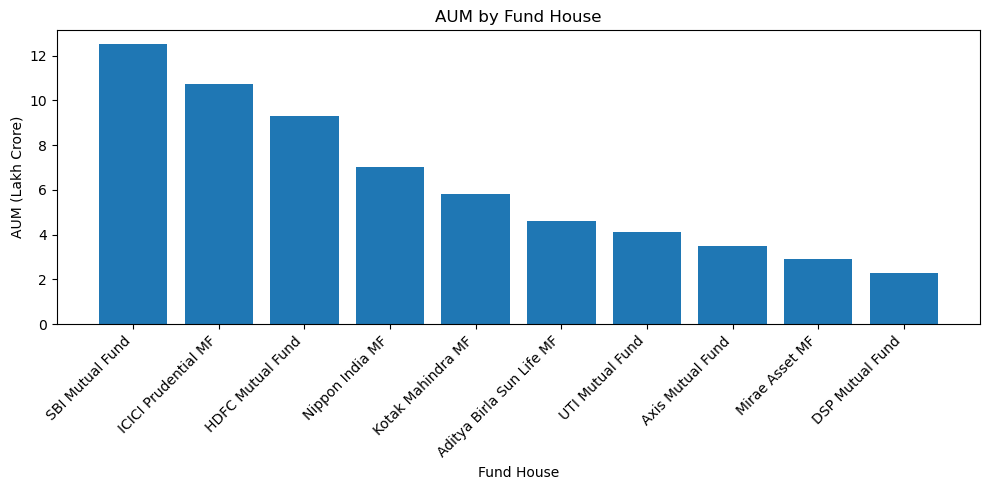

In [189]:
latest_date = df3["date"].max()

latest_aum = df3[df3["date"] == latest_date].sort_values(
    "aum_lakh_crore", ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(latest_aum["fund_house"], latest_aum["aum_lakh_crore"])

plt.title("AUM by Fund House")
plt.xlabel("Fund House")
plt.ylabel("AUM (Lakh Crore)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observation

The graph compares the Assets Under Management of different fund houses. A higher AUM indicates that the fund house manages a larger amount of investors' money.

## Dataset 4: Monthly SIP Inflows

This dataset shows the monthly amount invested in mutual funds through Systematic Investment Plans (SIPs).

In [190]:
df4 = pd.read_csv("data/04_monthly_sip_inflows.csv")
df4.head()

,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01,11517,4.91,9.10,4.80,NaN
1,2022-02,11438,4.93,8.20,4.85,NaN
2,2022-03,12328,5.09,10.50,5.01,NaN
3,2022-04,11863,5.48,9.52,5.12,NaN
4,2022-05,12286,5.55,8.10,5.15,NaN


In [191]:
df4.shape

(48, 6)

In [192]:
df4.columns

Index(['month', 'sip_inflow_crore', 'active_sip_accounts_crore',
       'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct'],
      dtype='object')

In [193]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   month                      48 non-null     object 
 1   sip_inflow_crore           48 non-null     int64  
 2   active_sip_accounts_crore  48 non-null     float64
 3   new_sip_accounts_lakh      48 non-null     float64
 4   sip_aum_lakh_crore         48 non-null     float64
 5   yoy_growth_pct             36 non-null     float64
dtypes: float64(4), int64(1), object(1)
memory usage: 2.4+ KB


In [194]:
df4.isnull().sum()

month                         0
sip_inflow_crore              0
active_sip_accounts_crore     0
new_sip_accounts_lakh         0
sip_aum_lakh_crore            0
yoy_growth_pct               12
dtype: int64

In [195]:
df4["yoy_growth_pct"]

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
5       NaN
6       NaN
7       NaN
8       NaN
9       NaN
10      NaN
11      NaN
12    20.31
13    19.66
14    15.80
15    24.33
16    20.05
17    20.02
18    25.58
19    24.58
20    23.63
21    29.82
22    28.31
23    29.74
24    35.96
25    40.18
26    42.69
27    38.12
28    44.16
29    44.31
30    53.05
31    48.90
32    52.78
33    49.59
34    48.30
35    50.25
36    40.14
37    35.50
38    27.27
39    30.73
40    25.52
41    28.28
42    22.00
43    20.04
44    19.80
45    16.61
46    19.27
47    17.17
Name: yoy_growth_pct, dtype: float64

In [196]:
df4["yoy_growth_pct"].describe()

count    36.000000
mean     31.456944
std      11.768190
min      15.800000
25%      20.245000
50%      28.295000
75%      40.807500
max      53.050000
Name: yoy_growth_pct, dtype: float64

In [197]:
df4["yoy_growth_pct"].mean()

np.float64(31.45694444444444)

In [198]:
df4["yoy_growth_pct"] = df4["yoy_growth_pct"].fillna(
    df4["yoy_growth_pct"].mean()
)

In [199]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   month                      48 non-null     object 
 1   sip_inflow_crore           48 non-null     int64  
 2   active_sip_accounts_crore  48 non-null     float64
 3   new_sip_accounts_lakh      48 non-null     float64
 4   sip_aum_lakh_crore         48 non-null     float64
 5   yoy_growth_pct             48 non-null     float64
dtypes: float64(4), int64(1), object(1)
memory usage: 2.4+ KB


In [200]:
df4.isnull().sum()

month                        0
sip_inflow_crore             0
active_sip_accounts_crore    0
new_sip_accounts_lakh        0
sip_aum_lakh_crore           0
yoy_growth_pct               0
dtype: int64

In [201]:
df4.duplicated().sum()

np.int64(0)

In [202]:
df4.describe()

,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
count,48.000000,48.000000,48.000000,48.000000,48.000000
mean,19577.520833,7.189583,9.893750,8.632083,31.456944
std,6354.329621,1.271457,5.370745,3.613579,10.155347
min,11438.000000,4.910000,7.500000,4.800000,15.800000
25%,13658.500000,6.110000,8.775000,5.790000,24.155000
50%,18224.000000,7.150000,9.200000,7.265000,31.456944
75%,25944.250000,8.300000,9.562500,10.525000,36.500000
max,31002.000000,9.350000,46.000000,15.900000,53.050000


In [203]:
df4["month"] = pd.to_datetime(df4["month"], errors="coerce")
df4.dtypes

month                        datetime64[ns]
sip_inflow_crore                      int64
active_sip_accounts_crore           float64
new_sip_accounts_lakh               float64
sip_aum_lakh_crore                  float64
yoy_growth_pct                      float64
dtype: object

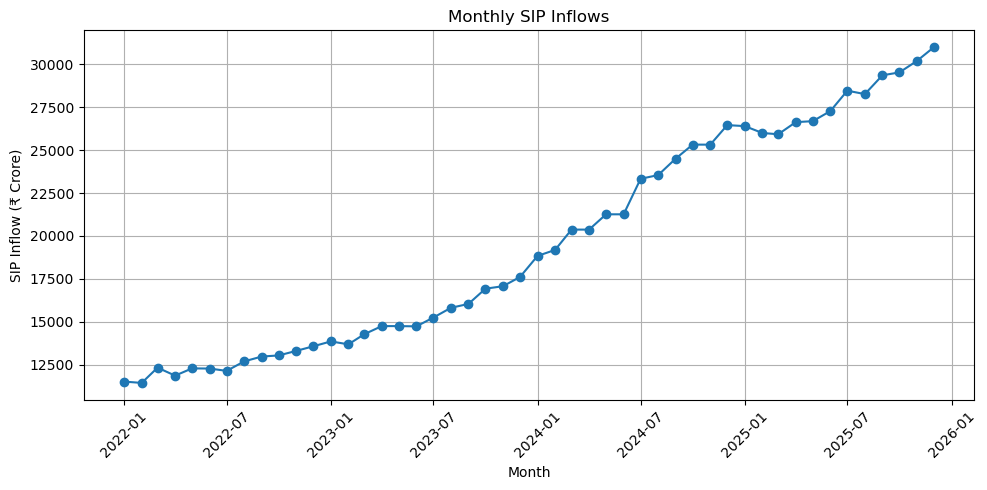

In [204]:
df4 = df4.sort_values("month")

plt.figure(figsize=(10, 5))
plt.plot(df4["month"], df4["sip_inflow_crore"], marker="o")

plt.title("Monthly SIP Inflows")
plt.xlabel("Month")
plt.ylabel("SIP Inflow (₹ Crore)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Insights

* The line chart shows a strong overall upward trend in monthly SIP inflows from 2022 to 2025. Although there are some month-to-month fluctuations, the inflow increases substantially over the period, indicating growing investor participation and increasing investments through systematic investment plans.

### Observation

The graph shows how SIP investments change over time. An increasing trend indicates growing participation of investors in mutual funds through systematic investment plans.

## Dataset 5: Category-wise Mutual Fund Inflows

This dataset shows the amount of investment flowing into different mutual fund categories.

In [205]:
df5 = pd.read_csv("data/05_category_inflows.csv")
df5.head()

,month,category,net_inflow_crore
0,2024-04,Large Cap,2413.0
1,2024-04,Mid Cap,3897.0
2,2024-04,Small Cap,3533.0
3,2024-04,Flexi Cap,4947.0
4,2024-04,Large & Mid Cap,4214.0


In [206]:
df5.shape

(144, 3)

In [207]:
df5.columns

Index(['month', 'category', 'net_inflow_crore'], dtype='object')

In [208]:
df5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   month             144 non-null    object 
 1   category          144 non-null    object 
 2   net_inflow_crore  144 non-null    float64
dtypes: float64(1), object(2)
memory usage: 3.5+ KB


In [209]:
df5.isnull().sum()

month               0
category            0
net_inflow_crore    0
dtype: int64

In [210]:
df5.duplicated().sum()

np.int64(0)

In [211]:
df5.describe()

,net_inflow_crore
count,144.000000
mean,6473.881944
std,9718.335947
min,437.000000
25%,1801.250000
50%,4148.000000
75%,5304.000000
max,41952.000000


In [212]:
df5["category"].value_counts()

category
Large Cap            12
Mid Cap              12
Small Cap            12
Flexi Cap            12
Large & Mid Cap      12
ELSS                 12
Value/Contra         12
Sectoral/Thematic    12
Liquid               12
Short Duration       12
Gilt                 12
Hybrid               12
Name: count, dtype: int64

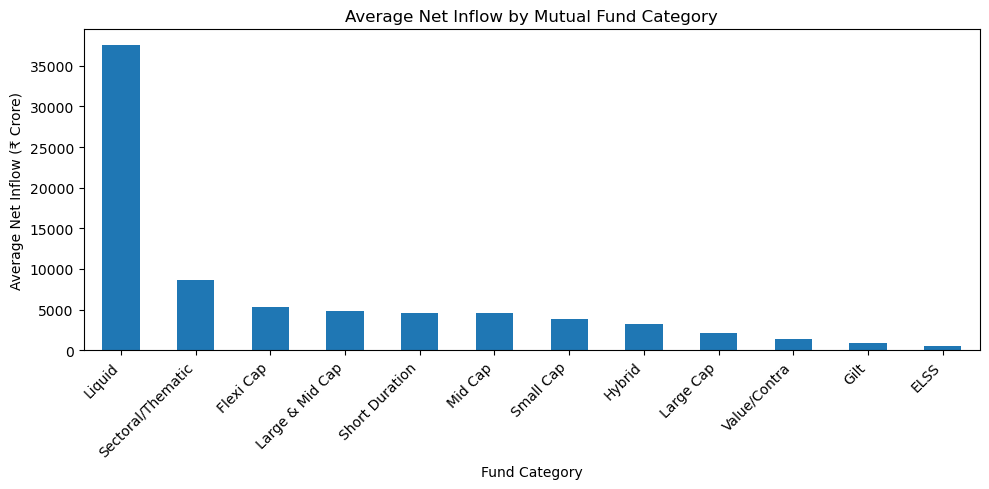

In [213]:
category_avg = df5.groupby("category")["net_inflow_crore"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
category_avg.plot(kind="bar")

plt.title("Average Net Inflow by Mutual Fund Category")
plt.xlabel("Fund Category")
plt.ylabel("Average Net Inflow (₹ Crore)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Insight
* The bar chart shows significant variation in average net inflows across mutual fund categories. Liquid funds have the highest average net inflow, followed by Sectoral/Thematic and Flexi Cap funds, while ELSS has the lowest. This indicates that investor money flows are concentrated more heavily in certain categories, particularly Liquid funds.

### Observation

The graph compares the average net inflow across different mutual fund categories. Categories with higher values attracted more investment during the observed period.

## Dataset 6: Industry Folio Count

This dataset shows the number of investor folios in the mutual fund industry over time.

In [214]:
df6 = pd.read_csv("data/06_industry_folio_count.csv")
df6.head()

,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01,13.26,9.28,1.86,0.80,1.33
1,2022-04,13.91,9.74,1.95,0.83,1.39
2,2022-07,13.85,9.69,1.94,0.83,1.38
3,2022-10,14.12,9.88,1.98,0.85,1.41
4,2023-01,14.81,10.37,2.07,0.89,1.48


In [215]:
df6.shape

(21, 6)

In [216]:
df6.columns

Index(['month', 'total_folios_crore', 'equity_folios_crore',
       'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore'],
      dtype='object')

In [217]:
df6.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   month                21 non-null     object 
 1   total_folios_crore   21 non-null     float64
 2   equity_folios_crore  21 non-null     float64
 3   debt_folios_crore    21 non-null     float64
 4   hybrid_folios_crore  21 non-null     float64
 5   others_folios_crore  21 non-null     float64
dtypes: float64(5), object(1)
memory usage: 1.1+ KB


In [218]:
df6.isnull().sum()

month                  0
total_folios_crore     0
equity_folios_crore    0
debt_folios_crore      0
hybrid_folios_crore    0
others_folios_crore    0
dtype: int64

In [219]:
df6.duplicated().sum()

np.int64(0)

In [220]:
df6.describe()

,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
count,21.000000,21.000000,21.000000,21.000000,21.000000
mean,19.829524,13.880476,2.776190,1.190000,1.983333
std,4.583376,3.207799,0.640308,0.274864,0.459079
min,13.260000,9.280000,1.860000,0.800000,1.330000
25%,15.540000,10.880000,2.180000,0.930000,1.550000
50%,19.980000,13.990000,2.800000,1.200000,2.000000
75%,23.890000,16.720000,3.340000,1.430000,2.390000
max,26.120000,18.280000,3.660000,1.570000,2.610000


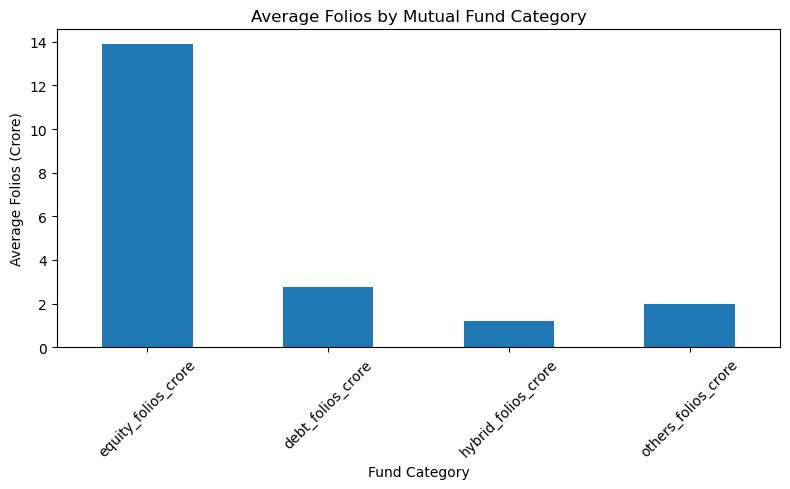

In [221]:
folio_avg = df6[
    ["equity_folios_crore", "debt_folios_crore",
     "hybrid_folios_crore", "others_folios_crore"]
].mean()

plt.figure(figsize=(8, 5))
folio_avg.plot(kind="bar")

plt.title("Average Folios by Mutual Fund Category")
plt.xlabel("Fund Category")
plt.ylabel("Average Folios (Crore)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

Equity funds have the highest number of investor folios compared with debt, hybrid, and other fund categories.

## Dataset 7: Scheme Performance

This dataset contains the performance and return information of different mutual fund schemes.

In [222]:
df7 = pd.read_csv("data/07_scheme_performance_clean.csv")
df7.head()

,amfi_code,scheme_name,fund_house,category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating,risk_grade
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,12.42,12.36,14.45,11.49,0.87,0.89,0.88,1.29,14.0,-21.70,14288,1.54,4,Moderate
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,Large Cap,Direct,15.25,11.30,14.23,9.52,1.78,0.87,0.81,1.29,14.0,-24.43,1231,0.66,3,Moderate
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Regular,24.56,23.39,20.67,22.16,1.23,0.89,0.94,1.35,25.0,-13.35,19259,1.43,5,Very High
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,Direct,20.59,23.14,21.82,22.01,1.13,1.04,0.93,1.67,25.0,-24.78,36061,0.72,4,Very High
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth,SBI Mutual Fund,Gilt,Regular,5.34,6.07,5.43,4.47,1.60,0.22,1.52,2.11,4.0,-2.30,24101,0.77,5,Low


In [223]:
df7.shape

(40, 19)

In [224]:
df7.columns

Index(['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan',
       'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct',
       'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio',
       'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct',
       'morningstar_rating', 'risk_grade'],
      dtype='object')

In [225]:
df7.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   amfi_code           40 non-null     int64  
 1   scheme_name         40 non-null     object 
 2   fund_house          40 non-null     object 
 3   category            40 non-null     object 
 4   plan                40 non-null     object 
 5   return_1yr_pct      40 non-null     float64
 6   return_3yr_pct      40 non-null     float64
 7   return_5yr_pct      40 non-null     float64
 8   benchmark_3yr_pct   40 non-null     float64
 9   alpha               40 non-null     float64
 10  beta                40 non-null     float64
 11  sharpe_ratio        40 non-null     float64
 12  sortino_ratio       40 non-null     float64
 13  std_dev_ann_pct     40 non-null     float64
 14  max_drawdown_pct    40 non-null     float64
 15  aum_crore           40 non-null     int64  
 16  expense_ra

In [226]:
df7.isnull().sum()

amfi_code             0
scheme_name           0
fund_house            0
category              0
plan                  0
return_1yr_pct        0
return_3yr_pct        0
return_5yr_pct        0
benchmark_3yr_pct     0
alpha                 0
beta                  0
sharpe_ratio          0
sortino_ratio         0
std_dev_ann_pct       0
max_drawdown_pct      0
aum_crore             0
expense_ratio_pct     0
morningstar_rating    0
risk_grade            0
dtype: int64

In [227]:
df7.duplicated().sum()

np.int64(0)

In [228]:
df7.describe()

,amfi_code,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating
count,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.00000,40.000000,40.000000
mean,120247.000000,14.376000,14.089000,14.516750,12.835500,1.253500,0.873250,1.361750,2.082500,14.962500,-19.200250,26091.60000,1.237000,4.250000
std,14534.998667,4.883023,4.617253,4.454021,4.740972,0.447412,0.224846,1.475805,2.203144,6.669282,8.819164,13809.11134,0.386584,0.742484
min,100016.000000,4.260000,5.140000,5.430000,3.960000,0.510000,0.220000,0.800000,1.030000,0.500000,-33.500000,979.00000,0.550000,3.000000
25%,118632.750000,11.735000,12.035000,12.340000,10.690000,0.887500,0.890000,0.865000,1.270000,14.000000,-25.062500,17400.50000,0.787500,4.000000
50%,119551.500000,14.620000,14.205000,14.185000,13.090000,1.205000,0.960000,0.925000,1.445000,14.000000,-20.600000,26713.00000,1.425000,4.000000
75%,120842.250000,16.392500,15.882500,17.585000,14.775000,1.700000,1.000000,0.985000,1.637500,19.000000,-14.255000,38125.00000,1.540000,5.000000
max,149324.000000,24.930000,23.390000,23.800000,22.160000,1.980000,1.040000,7.680000,10.370000,25.000000,-2.230000,49046.00000,1.640000,5.000000


In [229]:
df7.describe(include="object")

,scheme_name,fund_house,category,plan,risk_grade
count,40,40,40,40,40
unique,40,10,12,2,5
top,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,Moderate
freq,1,5,14,32,16


### Categorical Data Summary

The dataset contains 40 unique mutual fund schemes from 10 different fund houses and 12 fund categories. It includes 2 types of plans and 5 different risk grades. Most schemes are Regular plans, and Moderate is the most common risk grade.

Graph 1 — 1-Year, 3-Year & 5-Year Average Returns

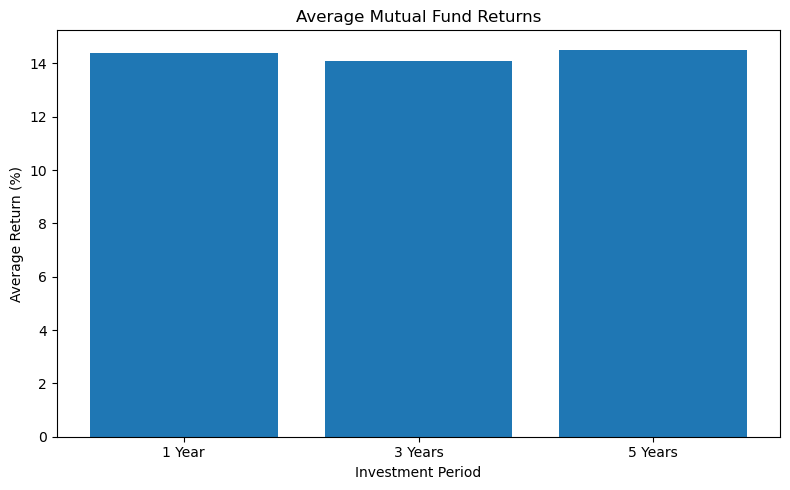

In [230]:
avg_returns = [
    df7["return_1yr_pct"].mean(),
    df7["return_3yr_pct"].mean(),
    df7["return_5yr_pct"].mean()
]

periods = ["1 Year", "3 Years", "5 Years"]

plt.figure(figsize=(8, 5))
plt.bar(periods, avg_returns)

plt.title("Average Mutual Fund Returns")
plt.xlabel("Investment Period")
plt.ylabel("Average Return (%)")
plt.tight_layout()
plt.show()

### Observation

The average returns are similar across the three investment periods. The 5-year return is slightly higher, indicating relatively stable long-term performance across the schemes.

Graph 2 — Risk vs Return

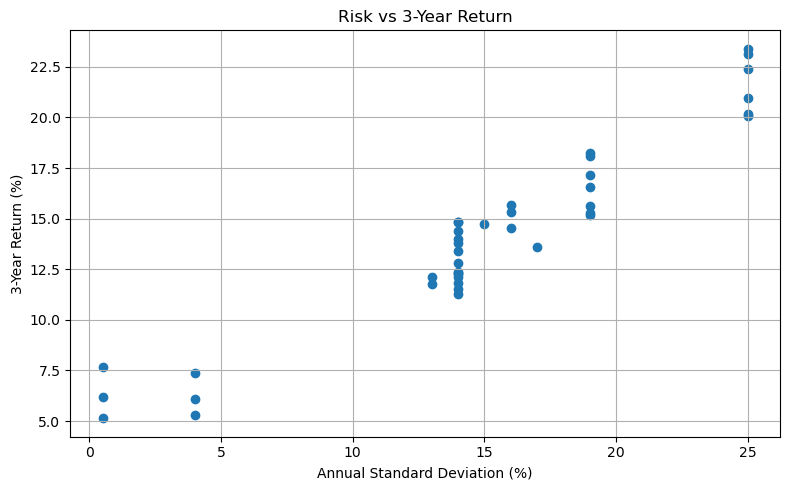

In [231]:
plt.figure(figsize=(8, 5))

plt.scatter(df7["std_dev_ann_pct"], df7["return_3yr_pct"])

plt.title("Risk vs 3-Year Return")
plt.xlabel("Annual Standard Deviation (%)")
plt.ylabel("3-Year Return (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation

* This graph shows the relationship between risk and return. Standard deviation represents the volatility of a fund, while the 3-year return represents its performance.
* The scatter plot indicates a positive relationship between annual standard deviation and 3-year return. Funds with higher volatility generally show higher 3-year returns, suggesting a risk-return trade-off. However, considerable variation exists among funds with similar risk levels, so higher risk does not necessarily guarantee higher returns.

### Observation

This graph shows the relationship between risk and return. Standard deviation represents the volatility of a fund, while the 3-year return represents its performance.

## Dataset 8: Investor Transactions

This dataset contains mutual fund investor transaction data, including purchases, redemptions, and investment activity.

In [232]:
df8 = pd.read_csv("data/08_investor_transactions_clean.csv")
df8.head()

,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified
1,INV002952,2024-01-01,148567,REDEMPTION,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified
3,INV003436,2024-01-01,118634,SIP,1102,Maharashtra,Mumbai,T30,36-45,Female,54.4,Cheque,Pending
4,INV004691,2024-01-01,119094,LUMPSUM,8682,Delhi,Noida,T30,26-35,Male,14.5,Net Banking,Pending


In [233]:
df8.shape

(32778, 13)

In [234]:
df8.columns

Index(['investor_id', 'transaction_date', 'amfi_code', 'transaction_type',
       'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender',
       'annual_income_lakh', 'payment_mode', 'kyc_status'],
      dtype='object')

In [235]:
df8.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32778 entries, 0 to 32777
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   investor_id         32778 non-null  object 
 1   transaction_date    32778 non-null  object 
 2   amfi_code           32778 non-null  int64  
 3   transaction_type    32778 non-null  object 
 4   amount_inr          32778 non-null  int64  
 5   state               32778 non-null  object 
 6   city                32778 non-null  object 
 7   city_tier           32778 non-null  object 
 8   age_group           32778 non-null  object 
 9   gender              32778 non-null  object 
 10  annual_income_lakh  32778 non-null  float64
 11  payment_mode        32778 non-null  object 
 12  kyc_status          32778 non-null  object 
dtypes: float64(1), int64(2), object(10)
memory usage: 3.3+ MB


In [236]:
df8.isnull().sum()

investor_id           0
transaction_date      0
amfi_code             0
transaction_type      0
amount_inr            0
state                 0
city                  0
city_tier             0
age_group             0
gender                0
annual_income_lakh    0
payment_mode          0
kyc_status            0
dtype: int64

In [237]:
df8.duplicated().sum()

np.int64(0)

In [238]:
df8.describe()

,amfi_code,amount_inr,annual_income_lakh
count,32778.000000,32778.000000,32778.000000
mean,120264.617518,107437.318628,26.181219
std,14370.205345,150415.905084,20.805425
min,100016.000000,400.000000,3.000000
25%,118632.000000,3153.000000,10.600000
50%,119551.000000,17782.500000,19.700000
75%,120843.000000,189324.250000,37.400000
max,149324.000000,597498.000000,99.700000


In [239]:
df8.describe(include="object")

,investor_id,transaction_date,transaction_type,state,city,city_tier,age_group,gender,payment_mode,kyc_status
count,32778,32778,32778,32778,32778,32778,32778,32778,32778,32778
unique,5000,516,3,12,24,2,5,2,4,2
top,INV001497,2025-04-28,SIP,Punjab,Kolkata,T30,26-35,Male,Net Banking,Verified
freq,12,88,19716,2965,2748,21719,13463,21809,8250,30146


### Statistical Summary

The dataset contains 32,778 investor transactions. The average transaction amount is around ₹1.07 lakh, while the average annual income of investors is about ₹26.18 lakh.

### Categorical Data Summary

The dataset contains 5,000 unique investors across different cities and states. SIP is the most common transaction type, and most investors have verified KYC status.

Transaction Type Graph

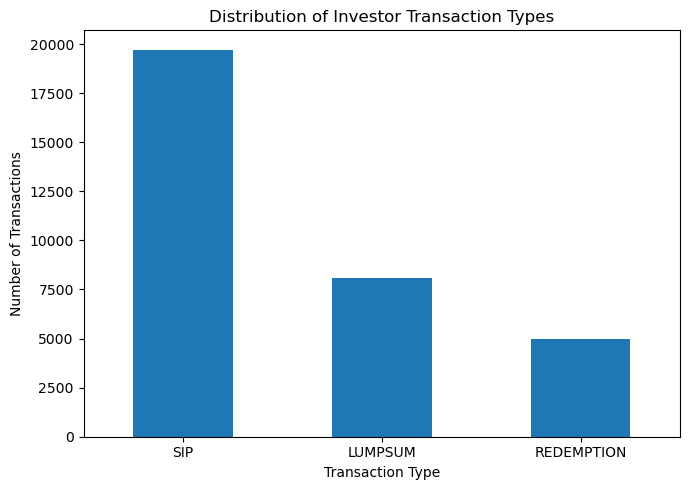

In [240]:
transaction_counts = df8["transaction_type"].value_counts()

plt.figure(figsize=(7, 5))
transaction_counts.plot(kind="bar")

plt.title("Distribution of Investor Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation

SIP is the most common transaction type, showing that systematic investments form a major part of investor activity in this dataset.

Transaction Type Graph

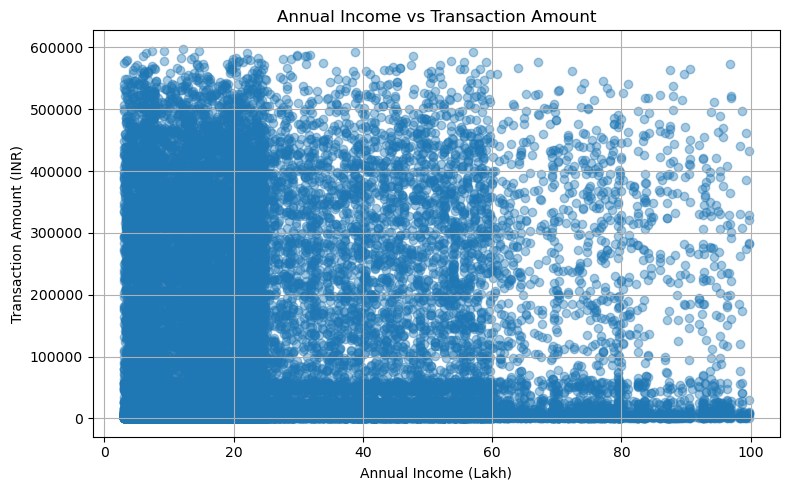

In [241]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df8["annual_income_lakh"],
    df8["amount_inr"],
    alpha=0.4
)

plt.title("Annual Income vs Transaction Amount")
plt.xlabel("Annual Income (Lakh)")
plt.ylabel("Transaction Amount (INR)")
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation

The graph shows the relationship between an investor's annual income and transaction amount. It helps identify whether investors with higher income generally invest larger amounts.

## Dataset 9: Portfolio Holdings

This dataset contains information about the securities and assets held by different mutual fund schemes in their portfolios.

In [242]:
df9 = pd.read_csv("data/09_portfolio_holdings.csv")
df9.head()

,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31


In [243]:
df9.shape

(322, 8)

In [244]:
df9.columns

Index(['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct',
       'market_value_cr', 'current_price_inr', 'portfolio_date'],
      dtype='object')

In [245]:
df9.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   amfi_code          322 non-null    int64  
 1   stock_symbol       322 non-null    object 
 2   stock_name         322 non-null    object 
 3   sector             322 non-null    object 
 4   weight_pct         322 non-null    float64
 5   market_value_cr    322 non-null    float64
 6   current_price_inr  322 non-null    float64
 7   portfolio_date     322 non-null    object 
dtypes: float64(3), int64(1), object(4)
memory usage: 20.3+ KB


In [246]:
df9.isnull().sum()

amfi_code            0
stock_symbol         0
stock_name           0
sector               0
weight_pct           0
market_value_cr      0
current_price_inr    0
portfolio_date       0
dtype: int64

In [247]:
df9.duplicated().sum()

np.int64(0)

In [248]:
df9.describe()

,amfi_code,weight_pct,market_value_cr,current_price_inr
count,322.000000,322.000000,322.000000,322.000000
mean,121210.434783,10.558975,1008.846646,4080.870528
std,14669.377920,6.060137,543.827535,2265.186353
min,100016.000000,0.990000,55.740000,246.780000
25%,118633.000000,6.015000,513.702500,2081.985000
50%,119552.000000,9.395000,1045.670000,4138.995000
75%,120842.750000,13.917500,1477.502500,5914.307500
max,149324.000000,38.180000,1999.500000,7942.960000


### Statistical Summary

The dataset contains 322 portfolio holdings. The average portfolio weight is about 10.56%, while the average market value is approximately ₹1,008.85 crore. The dataset also provides the current market price of each stock.

In [249]:
df9.describe(include="object")

,stock_symbol,stock_name,sector,portfolio_date
count,322,322,322,322
unique,30,30,14,1
top,BHARTIARTL,Bharti Airtel Ltd,Banking,2025-12-31
freq,15,15,60,322


### Categorical Data Summary

The dataset contains 30 different stocks from 14 sectors. Banking is the most frequently represented sector in the portfolio holdings.

Graph — Sector-wise Portfolio Holdings

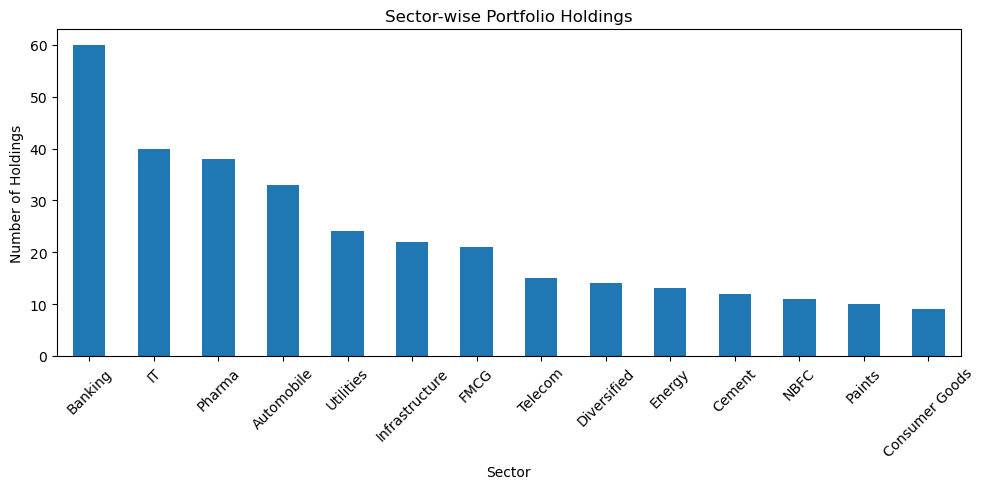

In [250]:
sector_counts = df9["sector"].value_counts()

plt.figure(figsize=(10, 5))
sector_counts.plot(kind="bar")

plt.title("Sector-wise Portfolio Holdings")
plt.xlabel("Sector")
plt.ylabel("Number of Holdings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The portfolio is diversified across multiple sectors, with the Banking sector having the highest number of holdings.

## Dataset 10: Benchmark Indices

This dataset contains historical values of market benchmark indices used to compare mutual fund performance with the overall market.

In [251]:
df10 = pd.read_csv("data/10_benchmark_indices.csv")
df10.head()

,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05
3,2022-01-06,NIFTY50,17878.51
4,2022-01-07,NIFTY50,17759.15


In [252]:
df10.shape

(8050, 3)

In [253]:
df10.columns

Index(['date', 'index_name', 'close_value'], dtype='object')

In [254]:
df10.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8050 entries, 0 to 8049
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         8050 non-null   object 
 1   index_name   8050 non-null   object 
 2   close_value  8050 non-null   float64
dtypes: float64(1), object(2)
memory usage: 188.8+ KB


In [255]:
df10.isnull().sum()

date           0
index_name     0
close_value    0
dtype: int64

In [256]:
df10.duplicated().sum()

np.int64(0)

In [257]:
df10.describe()

,close_value
count,8050.000000
mean,18351.950181
std,14169.995121
min,1444.130000
25%,2819.062500
50%,18392.960000
75%,26539.097500
max,79075.390000


### Statistical Summary

The dataset contains 8,050 benchmark observations. The average closing index value is approximately 18,351.95, with values ranging from 1,444.13 to 79,075.39.

In [258]:
df10.describe(include="object")

,date,index_name
count,8050,8050
unique,1150,7
top,2026-05-29,NIFTY50
freq,7,1150


### Categorical Data Summary

The dataset contains 7 different benchmark indices recorded across 1,150 unique dates. Each benchmark has historical closing values that can be used to compare market performance over time.

In [259]:
df10["date"] = pd.to_datetime(df10["date"])

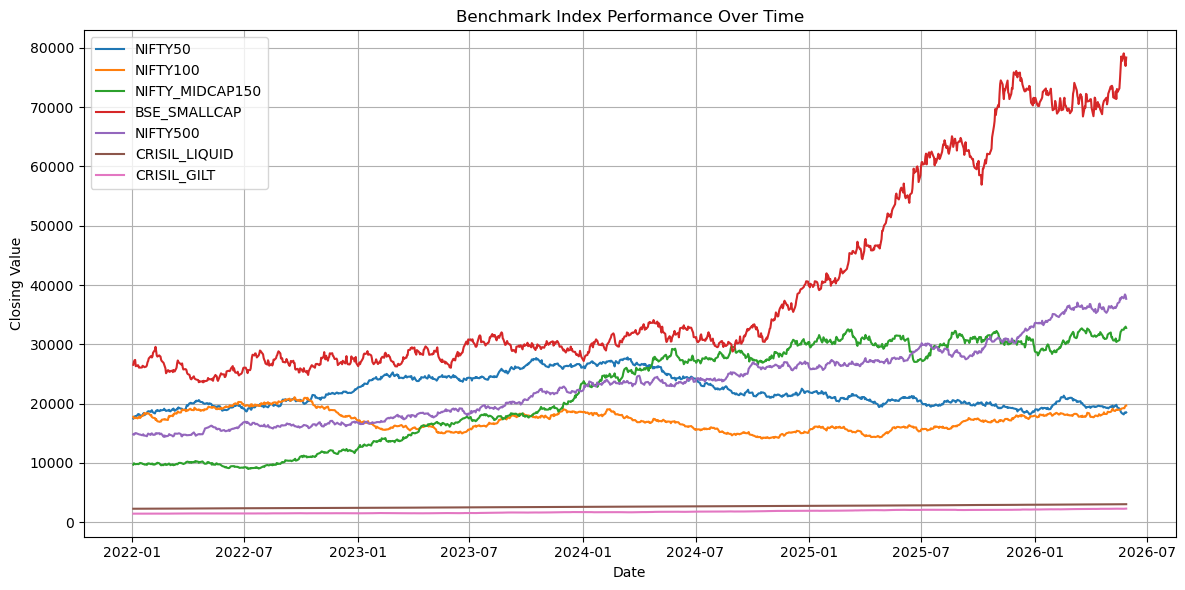

In [260]:
plt.figure(figsize=(12, 6))

for index in df10["index_name"].unique():
    temp = df10[df10["index_name"] == index].sort_values("date")
    plt.plot(temp["date"], temp["close_value"], label=index)

plt.title("Benchmark Index Performance Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation

The graph compares the historical movement of different benchmark indices. It shows how market indices change over time and helps in comparing mutual fund performance with overall market trends.

## Dataset 11–16: Live NAV Analysis

These datasets contain historical NAV values of six major mutual fund schemes from Axis, HDFC, ICICI, Kotak, Nippon, and SBI. They are used to compare NAV trends and fund performance over time.

In [261]:
axis = pd.read_csv("data/axis_bluechip_live_nav.csv")
hdfc = pd.read_csv("data/hdfc_top100_live_nav.csv")
icici = pd.read_csv("data/icici_bluechip_live_nav.csv")
kotak = pd.read_csv("data/kotak_bluechip_live_nav.csv")
nippon = pd.read_csv("data/nippon_largecap_live_nav.csv")
sbi = pd.read_csv("data/sbi_bluechip_live_nav.csv")

print("All 6 Live NAV datasets loaded successfully!")

All 6 Live NAV datasets loaded successfully!


Step 2 — Check Basic Information Together

In [262]:
nav_datasets = {
    "Axis Bluechip": axis,
    "HDFC Top 100": hdfc,
    "ICICI Bluechip": icici,
    "Kotak Bluechip": kotak,
    "Nippon Large Cap": nippon,
    "SBI Bluechip": sbi
}

for name, data in nav_datasets.items():
    print("\n", name)
    print("Shape:", data.shape)
    print("Columns:", list(data.columns))
    print("Missing Values:", data.isnull().sum().sum())
    print("Duplicates:", data.duplicated().sum())


 Axis Bluechip
Shape: (3566, 2)
Columns: ['date', 'nav']
Missing Values: 0
Duplicates: 0

 HDFC Top 100
Shape: (3092, 2)
Columns: ['date', 'nav']
Missing Values: 0
Duplicates: 0

 ICICI Bluechip
Shape: (3308, 2)
Columns: ['date', 'nav']
Missing Values: 0
Duplicates: 0

 Kotak Bluechip
Shape: (3302, 2)
Columns: ['date', 'nav']
Missing Values: 0
Duplicates: 0

 Nippon Large Cap
Shape: (3298, 2)
Columns: ['date', 'nav']
Missing Values: 0
Duplicates: 0

 SBI Bluechip
Shape: (3237, 2)
Columns: ['date', 'nav']
Missing Values: 0
Duplicates: 0


Statistical Summary

In [263]:
for name, data in nav_datasets.items():
    print("\n", name)
    display(data.describe())


 Axis Bluechip


,nav
count,3566.000000
mean,825.890099
std,440.269683
min,10.612300
25%,1063.418725
50%,1063.640000
75%,1063.640000
max,1063.779200



 HDFC Top 100


,nav
count,3092.000000
mean,89.972586
std,60.357519
min,12.777500
25%,40.190450
50%,61.220550
75%,130.282325
max,214.676700



 ICICI Bluechip


,nav
count,3308.000000
mean,33.760553
std,13.058994
min,0.000000
25%,24.887500
50%,29.515000
75%,43.672500
max,62.670000


... (2 outputs left out)


 Nippon Large Cap


,nav
count,3298.000000
mean,46.113755
std,27.593208
min,12.219100
25%,24.980525
50%,34.890450
75%,60.123825
max,106.127200



 SBI Bluechip


,nav
count,3237.000000
mean,109.947556
std,5.352558
min,99.742000
25%,105.896600
50%,109.965800
75%,114.646500
max,118.892900


Missing Values Check

In [264]:
for name, data in nav_datasets.items():
    print(name, "- Missing Values:", data.isnull().sum().sum())

Axis Bluechip - Missing Values: 0
HDFC Top 100 - Missing Values: 0
ICICI Bluechip - Missing Values: 0
Kotak Bluechip - Missing Values: 0
Nippon Large Cap - Missing Values: 0
SBI Bluechip - Missing Values: 0


Duplicate Rows Check

In [265]:
for name, data in nav_datasets.items():
    print(name, "- Duplicate Rows:", data.duplicated().sum())

Axis Bluechip - Duplicate Rows: 0
HDFC Top 100 - Duplicate Rows: 0
ICICI Bluechip - Duplicate Rows: 0
Kotak Bluechip - Duplicate Rows: 0
Nippon Large Cap - Duplicate Rows: 0
SBI Bluechip - Duplicate Rows: 0


Minimum and Maximum NAV

In [266]:
for name, data in nav_datasets.items():
    print("\n", name)
    print("Minimum NAV:", data["nav"].min())
    print("Maximum NAV:", data["nav"].max())
    print("Average NAV:", round(data["nav"].mean(), 2))


 Axis Bluechip
Minimum NAV: 10.6123
Maximum NAV: 1063.7792
Average NAV: 825.89

 HDFC Top 100
Minimum NAV: 12.7775
Maximum NAV: 214.6767
Average NAV: 89.97

 ICICI Bluechip
Minimum NAV: 0.0
Maximum NAV: 62.67
Average NAV: 33.76

 Kotak Bluechip
Minimum NAV: 30.5643
Maximum NAV: 281.1083
Average NAV: 101.96

 Nippon Large Cap
Minimum NAV: 12.2191
Maximum NAV: 106.1272
Average NAV: 46.11

 SBI Bluechip
Minimum NAV: 99.742
Maximum NAV: 118.8929
Average NAV: 109.95


### Observation

The six live NAV datasets were checked for their structure, missing values, duplicate records, and basic statistical information. The minimum, maximum, and average NAV values show that each mutual fund has a different NAV range and historical performance pattern.

### INSIGHTS:-

* Equity funds are the most common.
* Moderate risk is the most common risk level.
* SIP growth is positive.
* SIP is the most common transaction type.
* Investors aged 26–35 are the most active.

# Machine Learning Extension

## Sub-Problem Statement

Can mutual fund performance indicators be used to predict 3-year fund returns and classify the risk level of mutual funds?

In this part, Linear Regression will be used to predict the 3-year return of a mutual fund, while Logistic Regression will be used to classify funds into two risk groups.

The results of both models will be evaluated and compared using suitable performance metrics.

## 1. Import Required Libraries

We import the libraries required for data handling, visualization, model building, and evaluation.

In [267]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Scheme Performance Dataset

The Scheme Performance dataset contains information about mutual fund returns, risk, and performance indicators.

This dataset is selected because it contains suitable numerical features for applying regression and classification models.

In [268]:
df_ml = pd.read_csv("data/07_scheme_performance.csv")

df_ml.head()

,amfi_code,scheme_name,fund_house,category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating,risk_grade
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,12.42,12.36,14.45,11.49,0.87,0.89,0.88,1.29,14.0,-21.70,14288,1.54,4,Moderate
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,Large Cap,Direct,15.25,11.30,14.23,9.52,1.78,0.87,0.81,1.29,14.0,-24.43,1231,0.66,3,Moderate
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Regular,24.56,23.39,20.67,22.16,1.23,0.89,0.94,1.35,25.0,-13.35,19259,1.43,5,Very High
3,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Small Cap,Direct,20.59,23.14,21.82,22.01,1.13,1.04,0.93,1.67,25.0,-24.78,36061,0.72,4,Very High
4,119120,SBI Magnum Gilt Fund - Regular Plan - Growth,SBI Mutual Fund,Gilt,Regular,5.34,6.07,5.43,4.47,1.60,0.22,1.52,2.11,4.0,-2.30,24101,0.77,5,Low


In [269]:
df_ml.columns

Index(['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan',
       'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct',
       'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio',
       'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct',
       'morningstar_rating', 'risk_grade'],
      dtype='object')

## 3. Data Quality Check

Before applying machine learning, we check the dataset for missing values and duplicate records.

This helps ensure that the data used for modelling is suitable for analysis.

In [270]:
print("Missing values:")
print(df_ml.isnull().sum())

print("\nDuplicate rows:")
print(df_ml.duplicated().sum())

Missing values:
amfi_code             0
scheme_name           0
fund_house            0
category              0
plan                  0
return_1yr_pct        0
return_3yr_pct        0
return_5yr_pct        0
benchmark_3yr_pct     0
alpha                 0
beta                  0
sharpe_ratio          0
sortino_ratio         0
std_dev_ann_pct       0
max_drawdown_pct      0
aum_crore             0
expense_ratio_pct     0
morningstar_rating    0
risk_grade            0
dtype: int64

Duplicate rows:
0


### 3.1 Dataset Understanding and Missing-Value Audit

The Scheme Performance dataset is examined using its shape, column data types, numerical and categorical column lists, and missing-value counts and percentages. This audit supports informed preprocessing decisions. Missing values are not automatically filled or dropped; the treatment must be selected according to each column's meaning and distribution.

In [271]:
# Dataset structure and column types
print("Dataset shape:", df_ml.shape)
print("\nData types:")
display(df_ml.dtypes.to_frame(name="Data Type"))

print("\nNumerical columns:")
print(df_ml.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(df_ml.select_dtypes(include=["object", "category", "bool"]).columns.tolist())

missing_audit = pd.DataFrame({
    "Missing Count": df_ml.isna().sum(),
    "Missing Percentage": (df_ml.isna().mean() * 100).round(2)
})
display(missing_audit)

Dataset shape: (40, 19)

Data types:


,Data Type
amfi_code,int64
scheme_name,object
fund_house,object
category,object
plan,object
return_1yr_pct,float64
return_3yr_pct,float64
return_5yr_pct,float64
benchmark_3yr_pct,float64
alpha,float64



Numerical columns:
['amfi_code', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating']

Categorical columns:
['scheme_name', 'fund_house', 'category', 'plan', 'risk_grade']


,Missing Count,Missing Percentage
amfi_code,0,0.0
scheme_name,0,0.0
fund_house,0,0.0
category,0,0.0
plan,0,0.0
return_1yr_pct,0,0.0
return_3yr_pct,0,0.0
return_5yr_pct,0,0.0
benchmark_3yr_pct,0,0.0
alpha,0,0.0


# 4. Linear Regression

## Objective

The objective is to predict the 3-year return of a mutual fund using its available performance indicators.

### Target Variable
- return_3yr_pct

### Features
- return_1yr_pct
- return_5yr_pct
- benchmark_3yr_pct
- alpha
- beta
- sharpe_ratio
- sortino_ratio
- std_dev_ann_pct

Linear Regression is used because the target variable is a continuous numerical value.

In [272]:
reg_features = [
    "return_1yr_pct",
    "return_5yr_pct",
    "benchmark_3yr_pct",
    "alpha",
    "beta",
    "sharpe_ratio",
    "sortino_ratio",
    "std_dev_ann_pct"
]

X_reg = df_ml[reg_features]
y_reg = df_ml["return_3yr_pct"]

print("Features:", reg_features)
print("Target: return_3yr_pct")

Features: ['return_1yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct']
Target: return_3yr_pct


In [273]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train_reg.shape)
print("Testing data:", X_test_reg.shape)

Training data: (32, 8)
Testing data: (8, 8)


In [274]:
linear_model = LinearRegression()

linear_model.fit(X_train_reg, y_train_reg)

y_pred_reg = linear_model.predict(X_test_reg)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


## 5. Regression Model Evaluation

The Linear Regression model is evaluated using:

- MAE: Average prediction error.
- RMSE: Measures the size of prediction errors.
- R² Score: Shows how well the model explains variation in the target variable.

In [275]:
mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print("MAE :", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 3.4416913763379853e-15
RMSE: 4.710277376051325e-15
R² Score: 1.0


Regression Graph

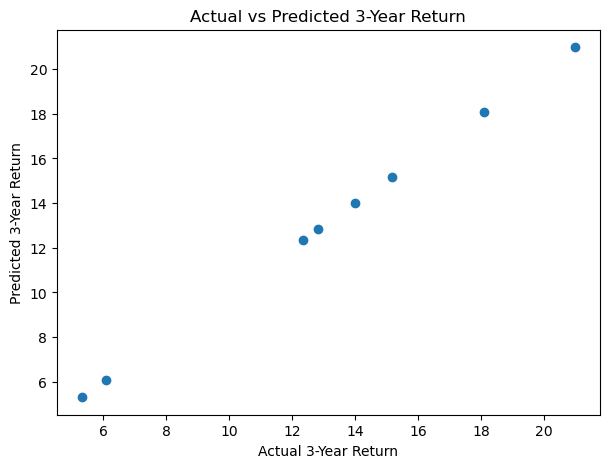

In [276]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test_reg, y_pred_reg)

plt.xlabel("Actual 3-Year Return")
plt.ylabel("Predicted 3-Year Return")
plt.title("Actual vs Predicted 3-Year Return")

plt.show()

### Observation

The Linear Regression model predicts the 3-year return using different fund performance indicators.

The R² score shows how well the selected features explain the variation in 3-year returns, while MAE and RMSE show the prediction error.

# 6. Logistic Regression

## Objective

The objective is to classify mutual funds into two risk groups using their performance indicators.

Since Logistic Regression is a classification algorithm, the original risk grades are converted into two classes.

In [277]:
df_ml["risk_grade"].value_counts()

risk_grade
Moderate           16
High                8
Very High           6
Low                 6
Moderately High     4
Name: count, dtype: int64

## 6.1 Creating Binary Risk Classes

The original dataset contains five risk grades. Since Logistic Regression is a binary classification algorithm, the risk grades are grouped into two classes:

- Lower Risk: Low and Moderate
- Higher Risk: Moderately High, High, and Very High

This allows us to classify mutual funds into two risk groups using their performance indicators.

In [278]:
# Create binary risk classes

df_ml["risk_class"] = df_ml["risk_grade"].map({
    "Low": 0,
    "Moderate": 0,
    "Moderately High": 1,
    "High": 1,
    "Very High": 1
})

df_ml["risk_class"].value_counts()

risk_class
0    22
1    18
Name: count, dtype: int64

In [279]:
pd.crosstab(df_ml["risk_grade"], df_ml["risk_class"])

risk_class,0,1
risk_grade,,
High,0,8
Low,6,0
Moderate,16,0
Moderately High,0,4
Very High,0,6


### Interpretation

The five original risk grades have been converted into two classes. 
Class 0 represents Lower Risk funds, while Class 1 represents Higher Risk funds.

This binary target can now be used for Logistic Regression.

In [280]:

# Checking our Machine Learning dataset

print("Dataset Shape:", df_ml.shape)

print("\nAvailable Columns:")
print(df_ml.columns.tolist())

print("\nRisk Class Distribution:")
print(df_ml["risk_class"].value_counts())

print("\nMissing Values:")
print(df_ml.isnull().sum().sum())


Dataset Shape: (40, 20)

Available Columns:
['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade', 'risk_class']

Risk Class Distribution:
risk_class
0    22
1    18
Name: count, dtype: int64

Missing Values:
0



## 6.2 Train-Test Split

We divide our dataset into two parts:
- 80% data for training the model.
- 20% data for testing its performance.

Stratified sampling maintains the proportion of both risk classes in the training and testing sets.


In [281]:

from sklearn.model_selection import train_test_split

# Select input features
classification_features = [
    "beta",
    "sharpe_ratio",
    "sortino_ratio",
    "std_dev_ann_pct",
    "max_drawdown_pct",
    "aum_crore",
    "expense_ratio_pct",
    "morningstar_rating",
    "category",
    "plan",
    "fund_house"
]

X_clf = df_ml[classification_features].copy()
y_clf = df_ml["risk_class"].copy()

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_clf,
    y_clf,
    test_size=0.20,
    random_state=42,
    stratify=y_clf
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training data: (32, 11)
Testing data: (8, 11)

Training class distribution:
risk_class
0    18
1    14
Name: count, dtype: int64

Testing class distribution:
risk_class
0    4
1    4
Name: count, dtype: int64



## 6.3 Logistic Regression Model

Logistic Regression is a supervised machine learning classification algorithm.

It learns patterns from mutual fund characteristics and predicts whether a fund belongs to the Lower Risk or Higher Risk category.


In [282]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Separate numerical and categorical features
num_features = [
    "beta", "sharpe_ratio", "sortino_ratio",
    "std_dev_ann_pct", "max_drawdown_pct",
    "aum_crore", "expense_ratio_pct", "morningstar_rating"
]

cat_features = ["category", "plan", "fund_house"]

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
])

# Create model pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!



## 6.4 Model Evaluation

After training, we test the Logistic Regression model on unseen data.

We use accuracy, precision, recall and F1-score to measure its classification performance.


In [283]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict risk classes
y_pred = logistic_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Lower Risk", "Higher Risk"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 87.5 %

Classification Report:
              precision    recall  f1-score   support

  Lower Risk       1.00      0.75      0.86         4
 Higher Risk       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8


Confusion Matrix:
[[3 1]
 [0 4]]



### Logistic Regression – Result

The Logistic Regression model achieved 87.5% accuracy on the testing dataset.

It correctly classified 3 Lower Risk funds and all 4 Higher Risk funds. The model showed good initial classification performance.

Since the testing dataset contains only 8 samples, further evaluation is required before selecting the final model.



## 6.5 K-Nearest Neighbors (KNN) Classification

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification.

It predicts the risk category of a mutual fund by comparing it with the K most similar funds in the training dataset. The majority class among its nearest neighbors determines the prediction.


In [284]:
from sklearn.neighbors import KNeighborsClassifier

In [285]:
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!



### 6.5.1 KNN Model Evaluation

The trained KNN model is evaluated on the testing dataset using accuracy, precision, recall, F1-score and a confusion matrix.


In [286]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict risk classes
knn_pred = knn_model.predict(X_test)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Model Accuracy:", round(knn_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    knn_pred,
    target_names=["Lower Risk", "Higher Risk"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_pred))


KNN Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

  Lower Risk       1.00      1.00      1.00         4
 Higher Risk       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8


Confusion Matrix:
[[4 0]
 [0 4]]



### KNN – Result

The K-Nearest Neighbors model achieved 100% accuracy on the testing dataset. It correctly classified all 8 mutual funds, including 4 Lower Risk and 4 Higher Risk funds.

KNN performed better than Logistic Regression on this particular test split. However, cross-validation is required for a more reliable comparison because the testing dataset is small.



## 6.6 Random Forest Classification



### 6.6.1 Understanding Random Forest

Random Forest is a supervised machine learning algorithm used for classification.

It creates multiple decision trees and combines their predictions. The final risk category is selected through majority voting among the trees.

It helps improve prediction stability and reduce overfitting compared with using a single decision tree.


In [287]:
from sklearn.ensemble import RandomForestClassifier

In [288]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!



### 6.6.2 Random Forest Model Evaluation

The Random Forest model is evaluated using accuracy, precision, recall, F1-score and a confusion matrix to measure its classification performance.


In [289]:

# Predict risk classes
rf_pred = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Lower Risk", "Higher Risk"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))


Random Forest Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

  Lower Risk       1.00      1.00      1.00         4
 Higher Risk       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8


Confusion Matrix:
[[4 0]
 [0 4]]



### 6.6.3 Random Forest – Result

The Random Forest model achieved 100% accuracy on the testing dataset. It correctly classified all 8 mutual funds, including 4 Lower Risk and 4 Higher Risk funds.

It performed better than Logistic Regression on this particular test split and matched the performance of KNN. Further cross-validation is required to confirm model reliability.



## 6.7 Comparison of Classification Models


In [290]:

import pandas as pd

# Compare model accuracy
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Random Forest"
    ],
    "Accuracy (%)": [
        accuracy * 100,
        knn_accuracy * 100,
        rf_accuracy * 100
    ]
})

print(comparison_df)


                 Model  Accuracy (%)
0  Logistic Regression          87.5
1                  KNN         100.0
2        Random Forest         100.0



### 6.7.1 Classification Model Accuracy Comparison

A bar chart is used to compare the accuracy of Logistic Regression, KNN and Random Forest models.


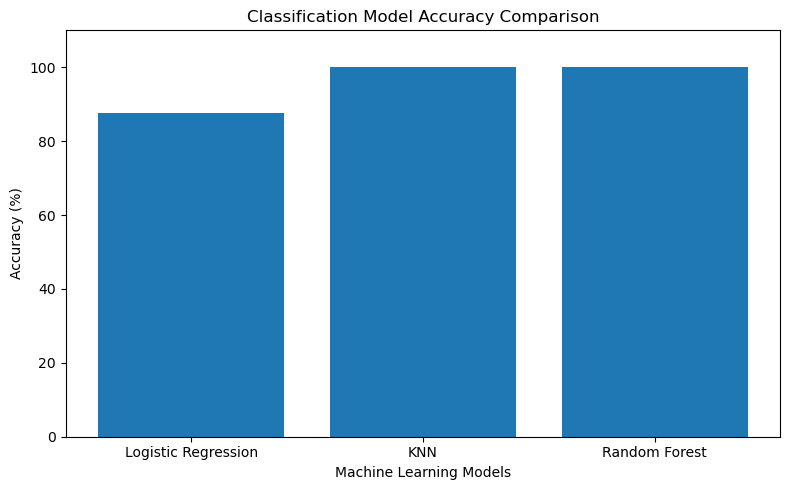

In [291]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy (%)"]
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()



# 7. Regression Models

Regression is a supervised machine learning technique used to predict continuous numerical values.

In this project, regression models will be used to predict mutual fund returns based on relevant financial features.

We will train and compare different regression algorithms using suitable evaluation metrics.



## 7.1 Preparing Data for Regression



### 7.1.1 Selecting Regression Target and Features

In this project, the target variable is `return_3yr_pct`, which represents the three-year mutual fund return.

We will use financial indicators such as beta, Sharpe ratio, Sortino ratio, standard deviation, maximum drawdown, AUM, expense ratio and Morningstar rating as input features.

Categorical features such as category, plan and fund house will also be included.

To avoid target leakage, benchmark return, alpha and other return-period columns will not be used as input features.

Note: This model estimates three-year returns from the available scheme-level data. It is not a future time-series forecasting model.


In [292]:

# Select features for regression
regression_features = [
    "beta",
    "sharpe_ratio",
    "sortino_ratio",
    "std_dev_ann_pct",
    "max_drawdown_pct",
    "aum_crore",
    "expense_ratio_pct",
    "morningstar_rating",
    "category",
    "plan",
    "fund_house"
]

# Input features and target
X_reg = df_ml[regression_features].copy()
y_reg = df_ml["return_3yr_pct"].copy()

print("Regression dataset shape:", X_reg.shape)
print("Target variable:", y_reg.name)
print("Missing values:", X_reg.isnull().sum().sum() + y_reg.isnull().sum())


Regression dataset shape: (40, 11)
Target variable: return_3yr_pct
Missing values: 0


In [293]:

from sklearn.model_selection import train_test_split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train_reg.shape)
print("Testing data:", X_test_reg.shape)


Training data: (32, 11)
Testing data: (8, 11)



## 7.2 Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

In this project, it will be used to estimate the three-year mutual fund return based on financial indicators such as risk, performance ratios, AUM and expense ratio.


In [294]:

from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
linear_model.fit(X_train_reg, y_train_reg)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!



### 7.2.1 Linear Regression Model Evaluation

The Linear Regression model is evaluated using three metrics:

- Mean Absolute Error (MAE): Measures the average absolute prediction error.
- Root Mean Squared Error (RMSE): Measures prediction error while giving more weight to larger errors.
- R² Score: Measures how well the model explains variations in the target variable.


In [295]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict three-year returns
y_pred_reg = linear_model.predict(X_test_reg)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print("Linear Regression Evaluation")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R² Score:", round(r2, 4))


Linear Regression Evaluation
MAE: 2.846
RMSE: 4.7975
R² Score: 0.0921



### 7.2.2 Linear Regression – Result

The Linear Regression model achieved an MAE of 2.846, RMSE of 4.7975 and R² score of 0.0921.

The low R² score indicates that the model explains only a small portion of the variation in mutual fund returns. Therefore, other regression algorithms will be tested to compare their performance.



## 7.3 K-Nearest Neighbors (KNN) Regression



### 7.3.1 Understanding KNN Regression

K-Nearest Neighbors (KNN) Regression is a supervised machine learning algorithm used to predict continuous numerical values.

It identifies the five most similar mutual funds based on their financial features and predicts the target return by calculating the average return of those neighboring funds.


In [296]:
from sklearn.neighbors import KNeighborsRegressor

knn_reg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", KNeighborsRegressor(n_neighbors=5))
])

# Train the model
knn_reg_model.fit(X_train_reg, y_train_reg)

print("KNN Regression model trained successfully!")

KNN Regression model trained successfully!


In [297]:
# Make predictions
knn_reg_pred = knn_reg_model.predict(X_test_reg)

# Calculate evaluation metrics
knn_reg_mae = mean_absolute_error(y_test_reg, knn_reg_pred)
knn_reg_rmse = np.sqrt(mean_squared_error(y_test_reg, knn_reg_pred))
knn_reg_r2 = r2_score(y_test_reg, knn_reg_pred)

print("KNN Regression Evaluation")
print("MAE:", round(knn_reg_mae, 4))
print("RMSE:", round(knn_reg_rmse, 4))
print("R² Score:", round(knn_reg_r2, 4))

KNN Regression Evaluation
MAE: 2.9512
RMSE: 3.3851
R² Score: 0.548


## 7.4 Random Forest Regression

Random Forest Regression is an ensemble learning algorithm that combines multiple decision trees to predict a continuous numerical value.

It uses the average predictions of multiple trees to estimate the three-year mutual fund return. 


### 7.4.1 Understanding Random Forest Regression

Random Forest Regression is a supervised machine learning algorithm used to predict continuous numerical values.

It combines multiple decision trees and calculates the average of their predictions to estimate the three-year mutual fund return.


### 7.4.2 Random Forest Regression Model

The Random Forest Regression model is implemented using the `RandomForestRegressor` algorithm from Scikit-learn.

The model uses multiple decision trees to learn the relationship between mutual fund characteristics and three-year returns.

The model is trained using the training dataset and then used to predict returns for the testing dataset.

In [298]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest Regression model
rf_reg_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Train the model
rf_reg_model.fit(X_train_reg, y_train_reg)

print("Random Forest Regression model trained successfully!")

Random Forest Regression model trained successfully!


### 7.4.3 Random Forest Regression Model Evaluation

After training the Random Forest Regression model, we evaluate its performance on the testing dataset.

The following evaluation metrics are used:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted returns.
- **Root Mean Squared Error (RMSE):** Measures prediction errors while giving more weight to larger errors.
- **R² Score:** Indicates how well the model explains the variation in mutual fund returns.

In [299]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
rf_reg_pred = rf_reg_model.predict(X_test_reg)

# Calculate evaluation metrics
rf_reg_mae = mean_absolute_error(y_test_reg, rf_reg_pred)

rf_reg_rmse = np.sqrt(
    mean_squared_error(y_test_reg, rf_reg_pred)
)

rf_reg_r2 = r2_score(y_test_reg, rf_reg_pred)

print("Random Forest Regression Evaluation")
print("MAE:", round(rf_reg_mae, 4))
print("RMSE:", round(rf_reg_rmse, 4))
print("R² Score:", round(rf_reg_r2, 4))

Random Forest Regression Evaluation
MAE: 1.3264
RMSE: 1.9361
R² Score: 0.8521


### 7.4.4 Random Forest Regression – Result

The Random Forest Regression model was trained to predict the three-year mutual fund returns using the selected financial indicators.

The model's performance was evaluated using MAE, RMSE and R² score.

The evaluation results help determine how accurately the model predicts mutual fund returns.

The performance of Random Forest Regression will be compared with Linear Regression and KNN Regression to identify the most suitable regression algorithm for this dataset.

## 7.5 Comparison of Regression Models

In this section, Linear Regression, KNN Regression and Random Forest Regression are compared using their evaluation metrics.

The comparison helps identify which model provides better predictions for three-year mutual fund returns.

A lower MAE and RMSE indicate smaller prediction errors, while a higher R² score indicates better explanatory performance.

In [300]:
# Create regression model comparison dataframe

regression_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "KNN Regression",
        "Random Forest Regression"
    ],

    "MAE": [
        mae,
        knn_reg_mae,
        rf_reg_mae
    ],

    "RMSE": [
        rmse,
        knn_reg_rmse,
        rf_reg_rmse
    ],

    "R² Score": [
        r2,
        knn_reg_r2,
        rf_reg_r2
    ]
})

print(regression_comparison.round(4))

                      Model     MAE    RMSE  R² Score
0         Linear Regression  2.8460  4.7975    0.0921
1            KNN Regression  2.9512  3.3851    0.5480
2  Random Forest Regression  1.3264  1.9361    0.8521


### 7.5.1 Regression Model Performance Comparison

A bar chart is created to compare the R² scores of the three regression models.

The model with the highest R² score shows better performance in explaining the variation in three-year mutual fund returns on the testing dataset.

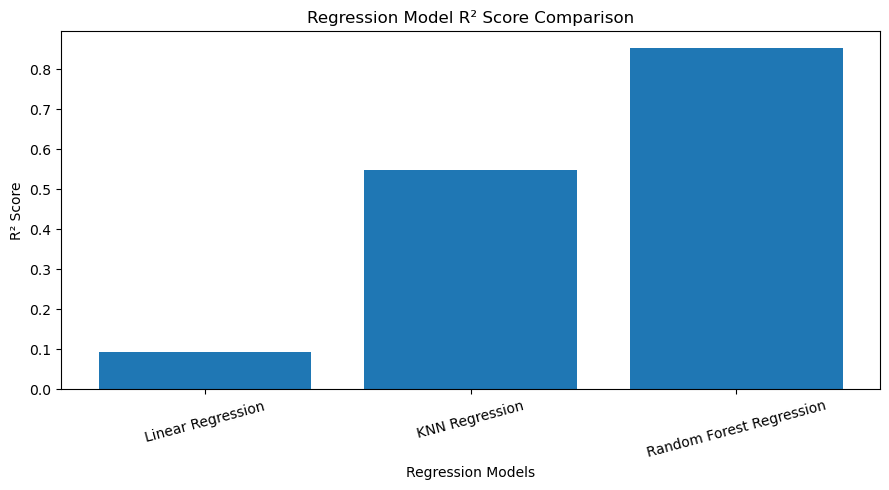

In [301]:


import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    regression_comparison["Model"],
    regression_comparison["R² Score"]
)

plt.title("Regression Model R² Score Comparison")
plt.xlabel("Regression Models")
plt.ylabel("R² Score")

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### 7.5.2 Regression Model Comparison – Observation

The comparison of Linear Regression, KNN Regression and Random Forest Regression helps evaluate their prediction performance.

The model with the lowest MAE and RMSE provides smaller prediction errors, while the model with the highest R² score explains a greater proportion of the variation in mutual fund returns.

The final model selection will be based on the overall evaluation results.


# 8. Additional Preprocessing Techniques

## 8.1 Binning / Discretization

Binning converts a continuous numerical variable into a smaller number of groups.

In this project, the three-year mutual fund returns are divided into three groups: Low Return, Medium Return, and High Return.

We use equal-frequency binning so that the groups contain approximately equal numbers of funds. This helps us understand return patterns more easily.

The binned column is used only for exploratory analysis and is not used as a model input feature.


In [302]:

# Create three return categories using equal-frequency binning

df_ml["return_3yr_category"] = pd.qcut(
    df_ml["return_3yr_pct"],
    q=3,
    labels=["Low Return", "Medium Return", "High Return"]
)

# Display the number of funds in each category
print("Funds in each return category:")
print(df_ml["return_3yr_category"].value_counts())

# Display the return range of each category
print("\nReturn range by category:")
print(
    df_ml.groupby("return_3yr_category", observed=True)["return_3yr_pct"]
    .agg(["min", "max", "median"])
)


Funds in each return category:
return_3yr_category
Low Return       14
Medium Return    13
High Return      13
Name: count, dtype: int64

Return range by category:
                       min    max  median
return_3yr_category                      
Low Return            5.14  12.33   11.42
Medium Return        12.36  15.29   14.41
High Return          15.34  23.39   18.23



## 8.2 Outlier Detection and Investigation

Outliers are observations that are unusually far from the other values in a dataset.

We use the Interquartile Range (IQR) method to identify potential outliers in numerical features.

The IQR is calculated as:

IQR = Q3 - Q1

The lower and upper limits are:

Lower Limit = Q1 - 1.5 × IQR

Upper Limit = Q3 + 1.5 × IQR

Mutual fund financial metrics may naturally contain extreme values because funds have different risk and return profiles. Therefore, potential outliers are investigated rather than automatically removed.


In [303]:
# Select numerical columns for outlier detection
outlier_columns = df_ml.select_dtypes(
    include=np.number
).columns.tolist()

# Exclude target column
if "risk_class" in outlier_columns:
    outlier_columns.remove("risk_class")

print("Columns selected for outlier detection:")
print(outlier_columns)

Columns selected for outlier detection:
['amfi_code', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating']


In [304]:

outlier_summary = []

for col in outlier_columns:
    Q1 = df_ml[col].quantile(0.25)
    Q3 = df_ml[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df_ml[col] < lower_limit) |
        (df_ml[col] > upper_limit)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Potential Outliers": outlier_count
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

display(outlier_summary_df.round(3))


,Feature,Lower Limit,Upper Limit,Potential Outliers
0,amfi_code,115318.500,124156.500,17
1,return_1yr_pct,4.749,23.379,3
2,return_3yr_pct,6.264,21.654,7
3,return_5yr_pct,4.472,25.452,0
4,benchmark_3yr_pct,4.563,20.902,5
5,alpha,-0.331,2.919,0
6,beta,0.725,1.165,6
7,sharpe_ratio,0.685,1.165,6
8,sortino_ratio,0.719,2.189,5
9,std_dev_ann_pct,6.500,26.500,6



### 8.2.1 Visualizing Potential Outliers

Boxplots are used to visually inspect the potential outliers identified by the IQR method.

The points outside the whiskers represent potential outliers. In mutual fund data, these observations may represent genuine differences in fund performance or risk.

Therefore, the observations are retained unless a data entry or measurement error is confirmed.


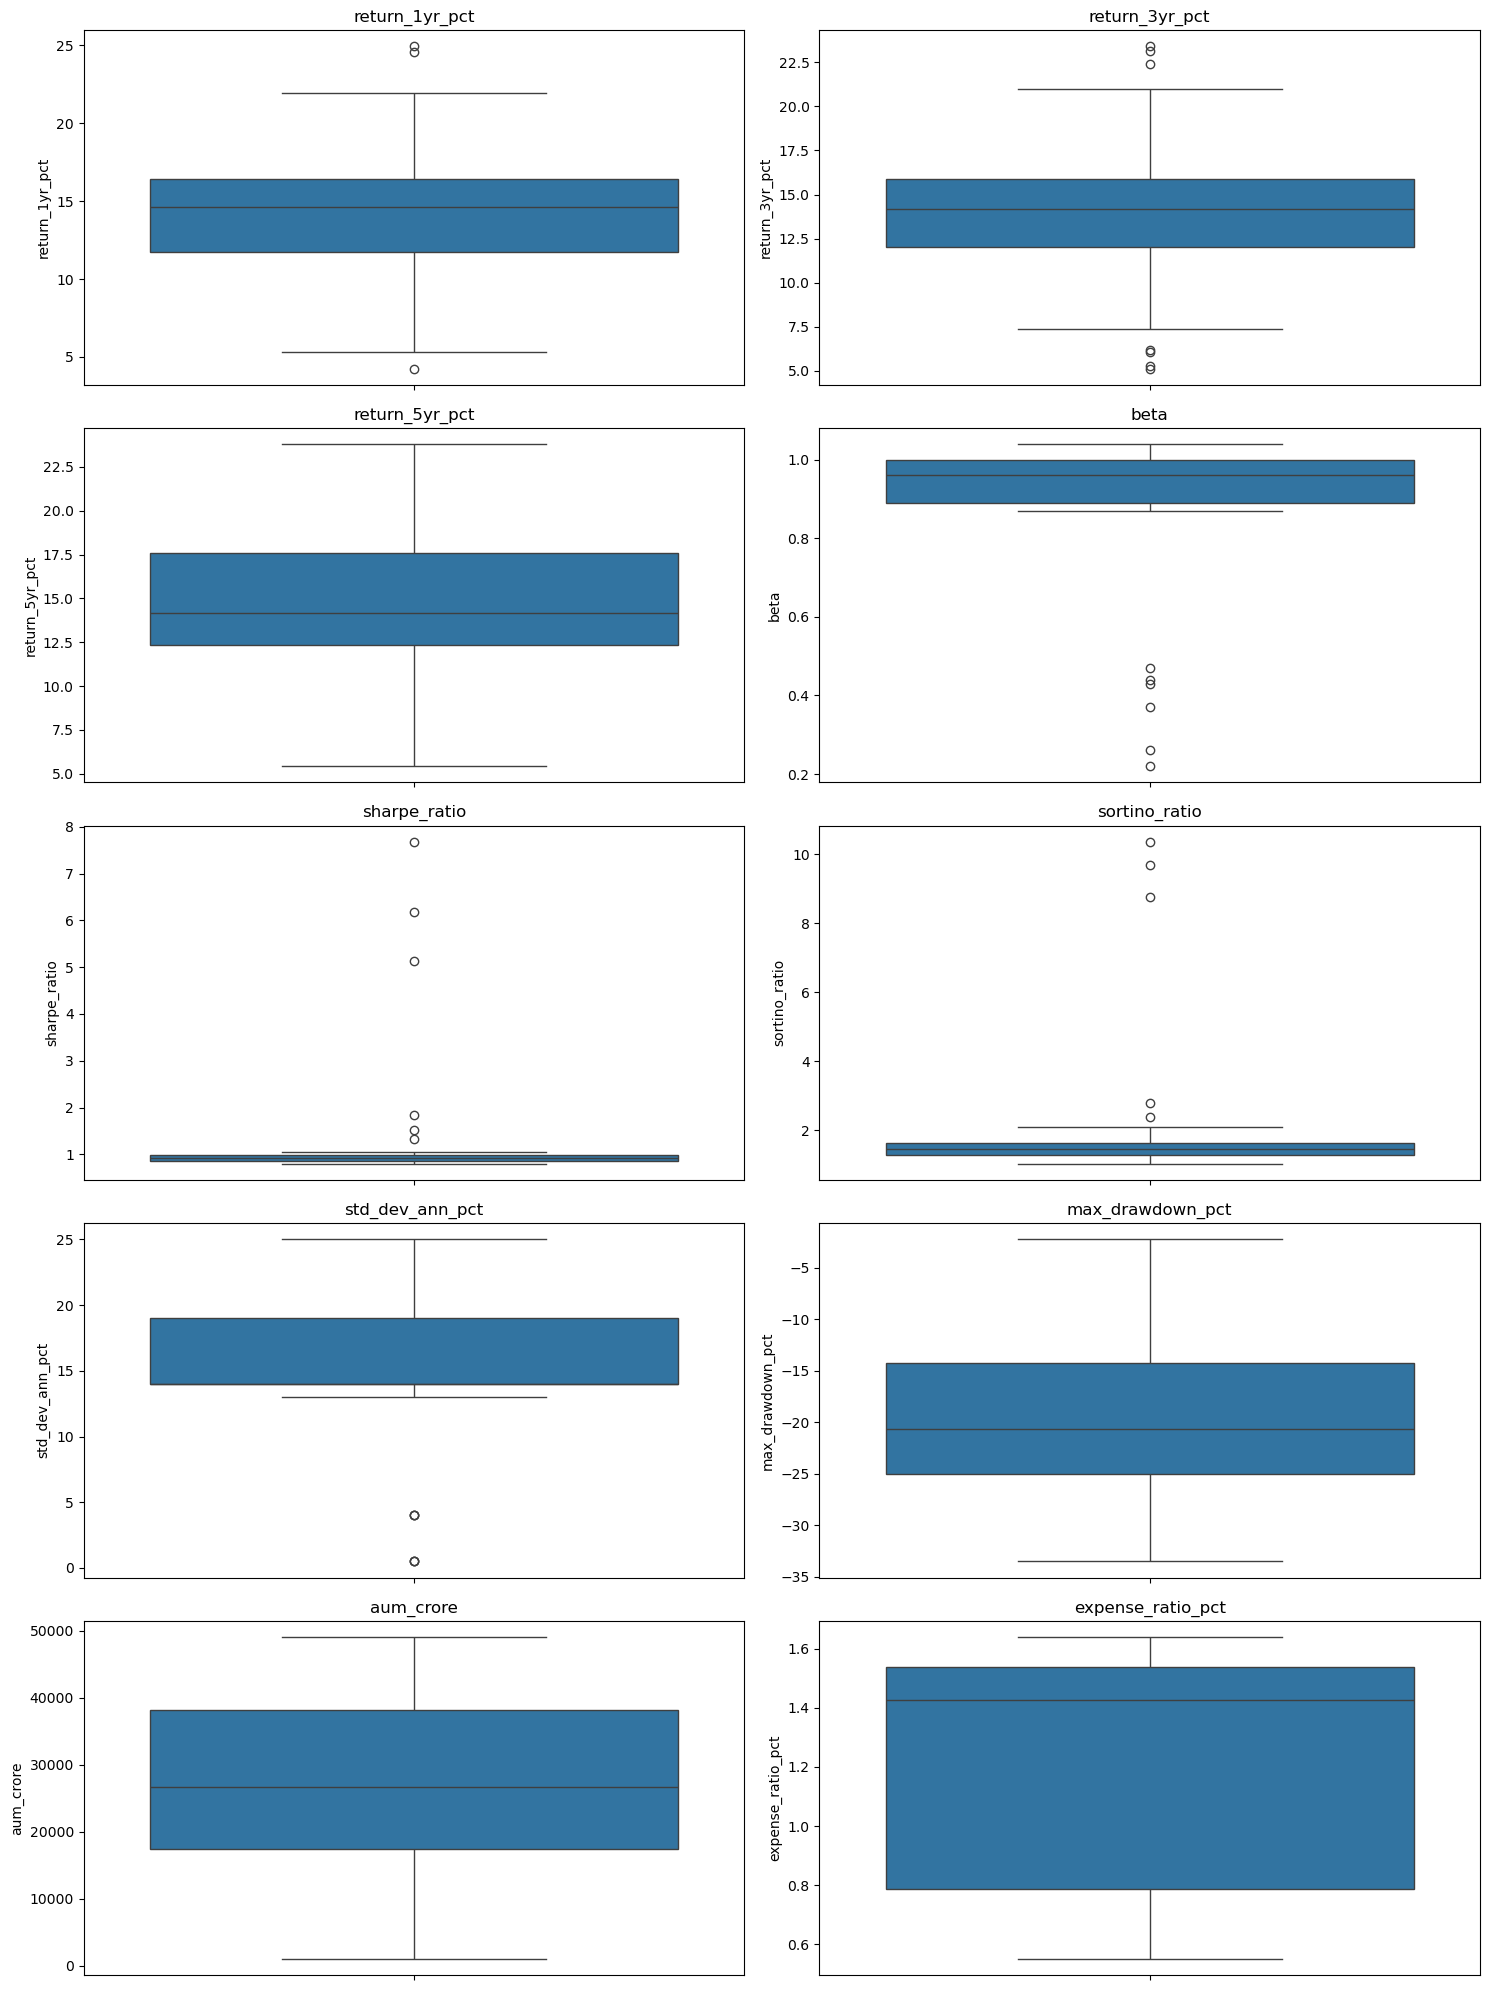

In [305]:

# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns

# List of numerical columns to check for outliers
outlier_columns = [
    "return_1yr_pct",
    "return_3yr_pct",
    "return_5yr_pct",
    "beta",
    "sharpe_ratio",
    "sortino_ratio",
    "std_dev_ann_pct",
    "max_drawdown_pct",
    "aum_crore",
    "expense_ratio_pct"
]

# Visualize potential outliers using boxplots
plt.figure(figsize=(15, 20))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(5, 2, i)
    sns.boxplot(y=df_ml[col])
    plt.title(col)

plt.tight_layout()
plt.show()



### 8.2.2 Outlier Treatment Decision

The IQR method identified potential outliers in several numerical features, including one-year returns, three-year returns, beta, Sharpe ratio, Sortino ratio, and annualized standard deviation.

The boxplots were used to visually inspect these observations.

Since extreme financial values may represent genuine differences in mutual fund performance and risk, the observations are retained in the dataset. No automatic outlier removal or capping is applied.

This decision helps preserve the original financial information and avoids removing potentially meaningful observations.



## 8.3 Feature Selection

Feature selection is the process of identifying the most relevant input features for a machine learning model.

It can reduce unnecessary complexity, improve interpretability, and help identify which financial indicators are most useful for predicting mutual fund risk.

In this project, Random Forest feature importance is used to rank the numerical features according to their contribution to the classification model.

The target variable is `risk_class`.


In [306]:

# Extract the trained Random Forest classifier

rf_classifier = rf_model.named_steps["classifier"]

# Get the transformed feature names from the preprocessing pipeline
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance values
feature_importances = rf_classifier.feature_importances_

# Create a feature importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 features
feature_importance_df.head(10)


,Feature,Importance
3,num__std_dev_ann_pct,0.333655
13,cat__category_Large Cap,0.178348
0,num__beta,0.096055
1,num__sharpe_ratio,0.079553
6,num__expense_ratio_pct,0.059428
2,num__sortino_ratio,0.046294
15,cat__category_Mid Cap,0.040972
4,num__max_drawdown_pct,0.040556
5,num__aum_crore,0.022882
20,cat__plan_Regular,0.013539



### 8.3.3 Feature Importance Visualization

A bar chart is used to visualize the feature importance scores obtained from the Random Forest classifier.

Features with higher importance scores contributed more to the model's predictions. These scores indicate predictive usefulness, but they do not establish a causal relationship with mutual fund risk.


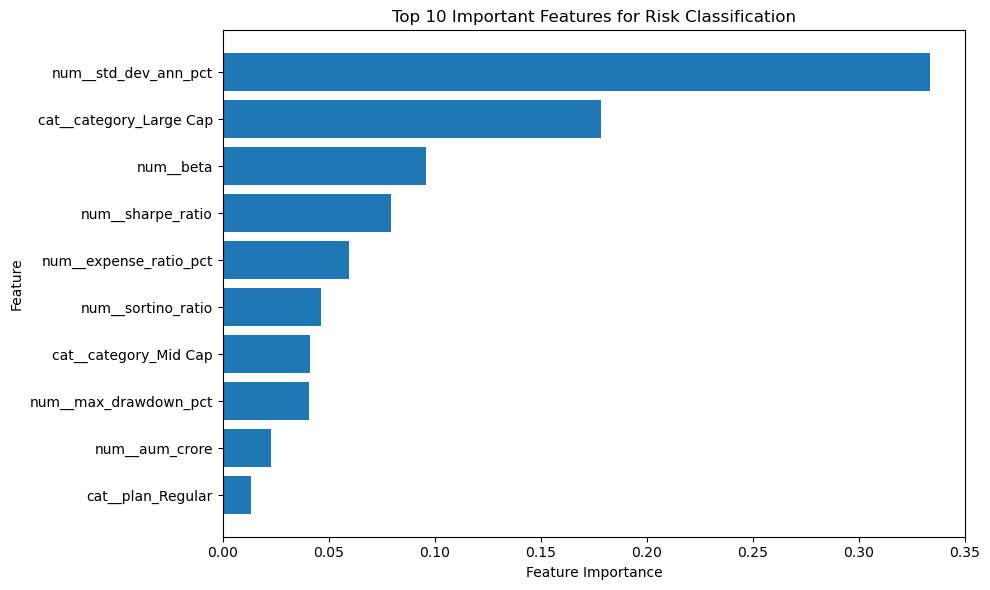

In [307]:

# Plot the top 10 most important features

top_features = feature_importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features for Risk Classification")

plt.tight_layout()
plt.show()



## 8.4 Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is a dimensionality reduction technique used to transform correlated numerical features into a smaller set of uncorrelated components.

PCA helps reduce the number of dimensions while retaining as much information (variance) as possible.

In this project, PCA is applied to scaled numerical features for analysis. The original classification and regression models continue to use their existing feature sets.


In [308]:

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select numerical features for PCA
pca_features = [
    "beta",
    "sharpe_ratio",
    "sortino_ratio",
    "std_dev_ann_pct",
    "max_drawdown_pct",
    "aum_crore",
    "expense_ratio_pct",
    "morningstar_rating"
]

# Prepare numerical data
X_pca = df_ml[pca_features].copy()

# Standardize features before PCA
pca_scaler = StandardScaler()
X_pca_scaled = pca_scaler.fit_transform(X_pca)

# Apply PCA while retaining 95% of the variance
pca_model = PCA(n_components=0.95, random_state=42)
X_pca_transformed = pca_model.fit_transform(X_pca_scaled)

print("Original number of features:", X_pca.shape[1])
print("Number of principal components:", X_pca_transformed.shape[1])
print(
    "Total explained variance:",
    round(pca_model.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Original number of features: 8
Number of principal components: 6
Total explained variance: 98.45 %



### 8.4.3 PCA Explained Variance Visualization

The explained variance ratio indicates the proportion of total information captured by each principal component.

The cumulative explained variance shows how much information is retained when multiple components are combined.

This visualization helps us understand how effectively PCA reduces the dimensionality of the numerical features.


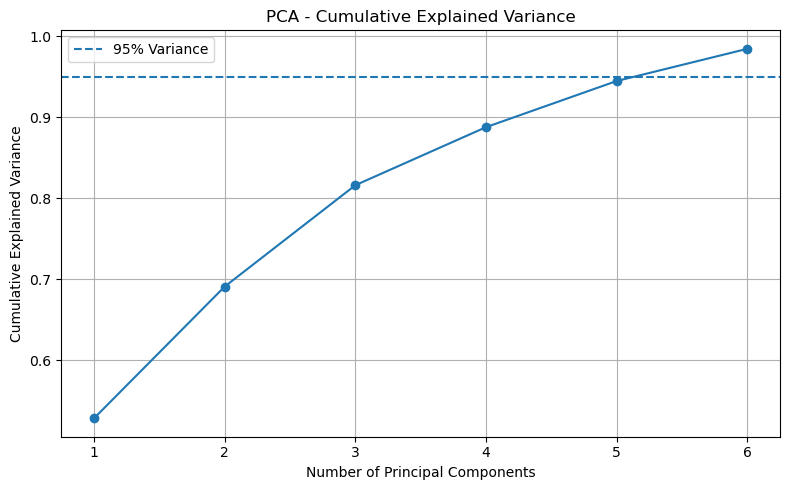

In [309]:

# Calculate cumulative explained variance

cumulative_variance = np.cumsum(
    pca_model.explained_variance_ratio_
)

# Plot explained variance
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% Variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



### 8.4.4 PCA Summary

PCA was applied to 8 standardized numerical features.

The number of principal components required to retain 95% of the total variance was determined by the PCA model.

The transformed dataset contains fewer dimensions than the original feature set, while preserving at least 95% of the variance.

PCA demonstrates how dimensionality reduction can simplify numerical data. The original features are retained for the main classification and regression models to preserve their interpretability.


### 8.4.5 PCA Feature-Retention Report

PCA was explored on the eight selected standardized numerical features. The number of retained components and cumulative explained variance are reported from the fitted PCA object below. These values describe the PCA exploration; the earlier classification and regression models continue to use their separately defined feature pipelines.

In [310]:
# Report PCA dimensions and retained variance from the fitted PCA object
if "pca" in globals() and hasattr(pca, "n_components_"):
    print("Original numerical features:", len(pca_features))
    print("Retained principal components:", pca.n_components_)
    print("Cumulative explained variance (%):",
          round(float(np.sum(pca.explained_variance_ratio_) * 100), 2))
elif "pca_model" in globals() and hasattr(pca_model, "n_components_"):
    print("Original numerical features:", len(pca_features))
    print("Retained principal components:", pca_model.n_components_)
    print("Cumulative explained variance (%):",
          round(float(np.sum(pca_model.explained_variance_ratio_) * 100), 2))
else:
    print("Run the PCA fitting cell above to display the retained component count and explained variance.")

Original numerical features: 8
Retained principal components: 6
Cumulative explained variance (%): 98.45



## 8.5 Summary of Preprocessing Techniques

The following table summarizes the preprocessing techniques used in the project and explains their purpose.

The preprocessing steps were selected based on the characteristics of the mutual fund dataset and the requirements of the machine learning models.


In [311]:

preprocessing_summary = pd.DataFrame({
    "Technique": [
        "Missing Value Check",
        "Categorical Encoding",
        "Feature Scaling",
        "Binning",
        "Outlier Detection",
        "Feature Selection",
        "Dimensionality Reduction"
    ],
    "Applied To": [
        "All dataset columns",
        "category, plan, fund_house",
        "Numerical model features",
        "return_3yr_pct",
        "Numerical features",
        "Classification and regression predictors",
        "8 numerical features using PCA"
    ],
    "Purpose": [
        "Identify missing data",
        "Convert categorical data into numerical form",
        "Bring numerical features to a comparable scale",
        "Create Low, Medium, and High return groups",
        "Identify unusually high or low values",
        "Remove target leakage and irrelevant columns",
        "Reduce dimensions while retaining information"
    ]
})

display(preprocessing_summary)


,Technique,Applied To,Purpose
0,Missing Value Check,All dataset columns,Identify missing data
1,Categorical Encoding,"category, plan, fund_house",Convert categorical data into numerical form
2,Feature Scaling,Numerical model features,Bring numerical features to a comparable scale
3,Binning,return_3yr_pct,"Create Low, Medium, and High return groups"
4,Outlier Detection,Numerical features,Identify unusually high or low values
5,Feature Selection,Classification and regression predictors,Remove target leakage and irrelevant columns
6,Dimensionality Reduction,8 numerical features using PCA,Reduce dimensions while retaining information



## 8.6 Train-Test Split and Data Leakage Prevention

The dataset is divided into training and testing sets before fitting the preprocessing steps.

The training set is used to learn preprocessing parameters and train the models. The testing set is kept separate to evaluate model performance on unseen data.

A fixed random state is used to make the split reproducible.

Preprocessing steps such as feature scaling and categorical encoding are implemented using Scikit-learn pipelines. This helps prevent data leakage by fitting preprocessing transformations only on the training data.


In [312]:

from sklearn.model_selection import train_test_split

# Define input features and target
X = df_ml.drop(columns=["risk_class"])
y = df_ml["risk_class"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (32, 20)
Testing features shape: (8, 20)
Training target shape: (32,)
Testing target shape: (8,)



### 8.6.2 Checking Class Distribution

The class distribution is checked after the train-test split to verify that both risk classes are represented in the training and testing sets.

Stratified splitting helps maintain a similar proportion of each class across the two sets.


In [313]:

# Check class distribution in the original dataset
print("Original Dataset Class Distribution:")
print(y.value_counts())

print("\nOriginal Dataset Class Proportion:")
print(y.value_counts(normalize=True).round(3))

# Check class distribution in the training set
print("\nTraining Set Class Distribution:")
print(y_train.value_counts())

print("\nTraining Set Class Proportion:")
print(y_train.value_counts(normalize=True).round(3))

# Check class distribution in the testing set
print("\nTesting Set Class Distribution:")
print(y_test.value_counts())

print("\nTesting Set Class Proportion:")
print(y_test.value_counts(normalize=True).round(3))


Original Dataset Class Distribution:
risk_class
0    22
1    18
Name: count, dtype: int64

Original Dataset Class Proportion:
risk_class
0    0.55
1    0.45
Name: proportion, dtype: float64

Training Set Class Distribution:
risk_class
0    18
1    14
Name: count, dtype: int64

Training Set Class Proportion:
risk_class
0    0.562
1    0.438
Name: proportion, dtype: float64

Testing Set Class Distribution:
risk_class
0    4
1    4
Name: count, dtype: int64

Testing Set Class Proportion:
risk_class
0    0.5
1    0.5
Name: proportion, dtype: float64



## 8.7 Classification Preprocessing Pipeline

A preprocessing pipeline is created to prepare numerical and categorical features for classification.

Numerical features are standardized using StandardScaler. Categorical features are converted into numerical representations using OneHotEncoder.

A ColumnTransformer combines both preprocessing steps. The transformations are fitted on the training data and then applied to the testing data to prevent data leakage.


In [314]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Define numerical and categorical feature columns
numeric_features = [
    "beta",
    "sharpe_ratio",
    "sortino_ratio",
    "std_dev_ann_pct",
    "max_drawdown_pct",
    "aum_crore",
    "expense_ratio_pct",
    "morningstar_rating"
]

categorical_features = [
    "category",
    "plan",
    "fund_house"
]

# Create numerical preprocessing pipeline
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

# Create categorical preprocessing pipeline
categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Classification preprocessing pipeline created successfully.")


Classification preprocessing pipeline created successfully.


In [315]:

# Fit the preprocessing pipeline using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing pipeline to testing data
X_test_processed = preprocessor.transform(X_test)

# Display transformed data shapes
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

print("\nPreprocessing completed successfully.")


Processed training data shape: (32, 31)
Processed testing data shape: (8, 31)

Preprocessing completed successfully.


In [316]:

# Get feature names after preprocessing
transformed_feature_names = preprocessor.get_feature_names_out()

# Display the transformed feature names
print("Total features before preprocessing:", X_train.shape[1])
print("Total features after preprocessing:", len(transformed_feature_names))

print("\nTransformed Feature Names:")
for feature in transformed_feature_names:
    print(feature)


Total features before preprocessing: 20
Total features after preprocessing: 31

Transformed Feature Names:
num__beta
num__sharpe_ratio
num__sortino_ratio
num__std_dev_ann_pct
num__max_drawdown_pct
num__aum_crore
num__expense_ratio_pct
num__morningstar_rating
cat__category_ELSS
cat__category_Flexi Cap
cat__category_Gilt
cat__category_Index/ETF
cat__category_Large & Mid Cap
cat__category_Large Cap
cat__category_Liquid
cat__category_Mid Cap
cat__category_Short Duration
cat__category_Small Cap
cat__category_Value
cat__plan_Direct
cat__plan_Regular
cat__fund_house_Aditya Birla Sun Life MF
cat__fund_house_Axis Mutual Fund
cat__fund_house_DSP Mutual Fund
cat__fund_house_HDFC Mutual Fund
cat__fund_house_ICICI Prudential MF
cat__fund_house_Kotak Mahindra MF
cat__fund_house_Mirae Asset MF
cat__fund_house_Nippon India MF
cat__fund_house_SBI Mutual Fund
cat__fund_house_UTI Mutual Fund


### 8.7.1 Encoding and Scaling – Method Justification

The classification preprocessing pipeline applies **StandardScaler** to numerical features so that variables measured on different scales are comparable. This is especially important for distance-based KNN and scale-sensitive models such as Logistic Regression.

The nominal categorical features `category`, `plan`, and `fund_house` are processed using **OneHotEncoder** because they do not have a natural order. The preprocessor is fitted only on the training data and then applied to the test data to reduce data leakage.

### 8.7.2 Numerical Skewness Investigation

Skewness is checked to identify numerical variables with asymmetric distributions. A high absolute skewness value can indicate that a transformation may be worth investigating. No log transformation is claimed or applied by this audit; any transformation should be selected only after checking the variable's meaning and whether its values permit that transformation.

In [317]:
# Inspect skewness of numerical predictors in the modelling dataset
numeric_audit = df_ml.select_dtypes(include=np.number).drop(
    columns=["risk_class"], errors="ignore"
)
skewness_summary = numeric_audit.skew().sort_values(
    key=lambda values: values.abs(), ascending=False
)
display(skewness_summary.to_frame(name="Skewness").round(3))

,Skewness
sharpe_ratio,3.482
sortino_ratio,3.271
beta,-1.951
amfi_code,0.711
expense_ratio_pct,-0.644
std_dev_ann_pct,-0.593
morningstar_rating,-0.445
max_drawdown_pct,0.415
aum_crore,-0.276
return_5yr_pct,0.130



## 8.8 Classification Model Training

### 8.8.1 Logistic Regression

Logistic Regression is used as the baseline classification model to predict the risk class of a mutual fund.

The model is trained using the preprocessed training data. Its performance is evaluated on the separate testing data.


In [318]:

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Train the model using the processed training data
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


In [319]:

# Predict risk classes for the test dataset
y_pred_logistic = logistic_model.predict(X_test_processed)

# Display actual and predicted values
prediction_results = pd.DataFrame({
    "Actual Risk Class": y_test.values,
    "Predicted Risk Class": y_pred_logistic
})

display(prediction_results)


,Actual Risk Class,Predicted Risk Class
0,0,0
1,0,1
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,1,1


In [320]:

from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", round(logistic_accuracy, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic, zero_division=0))


Logistic Regression Accuracy: 0.875

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.75      0.86         4
           1       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



8.8.5 — Confusion Matrix

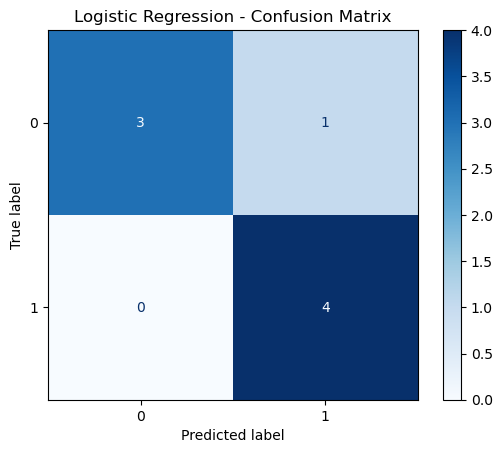

In [321]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_logistic)

# Display confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.classes_
)

cm_display.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()



### Logistic Regression – Model Summary

Logistic Regression was trained to classify mutual funds into risk classes using the processed training data. The model was evaluated on the test dataset using accuracy, precision, recall, F1-score, and a confusion matrix.

The evaluation results help us understand how well the model identifies each risk class. Since the dataset contains a limited number of mutual fund records, the results should be interpreted cautiously and may not generalize to a larger dataset.



### 8.9 – K-Nearest Neighbors (KNN) Classifier

K-Nearest Neighbors is a classification algorithm that predicts the class of a new observation based on the classes of its nearest data points.

Since KNN uses distances between observations, the numerical features are standardized before training. The model will be evaluated using the same test dataset as Logistic Regression for a fair comparison.


In [322]:

from sklearn.neighbors import KNeighborsClassifier

# Create and train the KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_processed, y_train)

print("KNN Classifier trained successfully.")


KNN Classifier trained successfully.


In [323]:

# Predict risk classes using KNN
y_pred_knn = knn_model.predict(X_test_processed)

# Display actual and predicted values
knn_prediction_results = pd.DataFrame({
    "Actual Risk Class": y_test.values,
    "Predicted Risk Class": y_pred_knn
})

display(knn_prediction_results)


,Actual Risk Class,Predicted Risk Class
0,0,0
1,0,0
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,1,1


In [324]:

# Predict risk classes using KNN
y_pred_knn = knn_model.predict(X_test_processed)

# Display actual and predicted values
knn_prediction_results = pd.DataFrame({
    "Actual Risk Class": y_test.values,
    "Predicted Risk Class": y_pred_knn
})

display(knn_prediction_results)


,Actual Risk Class,Predicted Risk Class
0,0,0
1,0,0
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,1,1


8.9.5 — Logistic Regression vs KNN

In [325]:

# Compare classification model accuracy
classification_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "K-Nearest Neighbors"],
    "Accuracy": [logistic_accuracy, knn_accuracy]
})

display(classification_comparison)


,Model,Accuracy
0,Logistic Regression,0.875
1,K-Nearest Neighbors,1.000



### 8.10 – Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make a prediction. For classification, the final prediction is based on the majority vote of the individual trees.

Random Forest can capture non-linear relationships between mutual fund features and risk classes. We will train it using the same processed training data and evaluate it on the same test dataset.


In [326]:

from sklearn.ensemble import RandomForestClassifier

# Create and train the Random Forest classifier
rf_classifier_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_classifier_model.fit(X_train_processed, y_train)

print("Random Forest Classifier trained successfully.")


Random Forest Classifier trained successfully.


In [327]:

# Predict risk classes using Random Forest
y_pred_rf = rf_classifier_model.predict(X_test_processed)

# Display actual and predicted values
rf_prediction_results = pd.DataFrame({
    "Actual Risk Class": y_test.values,
    "Predicted Risk Class": y_pred_rf
})

display(rf_prediction_results)


,Actual Risk Class,Predicted Risk Class
0,0,0
1,0,0
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,1,1


In [328]:

from sklearn.metrics import accuracy_score, classification_report

# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


Random Forest Accuracy: 1.0

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



In [329]:

# Compare all classification models
classification_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        knn_accuracy,
        rf_accuracy
    ]
})

classification_comparison = classification_comparison.sort_values(
    by="Accuracy",
    ascending=False
)

display(classification_comparison)


,Model,Accuracy
1,K-Nearest Neighbors,1.000
2,Random Forest,1.000
0,Logistic Regression,0.875



### Classification Model Comparison – Observation

The performance of Logistic Regression, K-Nearest Neighbors, and Random Forest was compared using test accuracy. The model with the highest test accuracy performed best on this particular test split.

However, the dataset and test set are small. Therefore, the comparison is preliminary, and further validation on a larger dataset is required before using the model for real-world mutual fund risk classification.



## 8.11 – Regression Model Comparison

Regression models are used to predict the continuous value of a mutual fund's 3-year return (`return_3yr_pct`).

The models are evaluated using:
- **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted returns.
- **RMSE (Root Mean Squared Error):** Gives higher penalty to larger prediction errors.
- **R² Score:** Measures how much variation in the target is explained by the model.

All models are evaluated using the same test dataset for a fair comparison.



### Regression Model Results – Summary

The regression models were evaluated using MAE, RMSE, and R² score to measure their prediction performance for mutual fund 3-year returns.

The results from the earlier regression experiments will be used for interpretation. Lower MAE and RMSE indicate smaller prediction errors, while a higher R² score indicates that the model explains more variation in the target.

The dataset is limited in size, so the regression results should be treated as preliminary. More data and further validation are required before using these models for real-world return prediction.


In [330]:

import joblib
from pathlib import Path

# Model files save karne ke liye folder
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save trained classification model
joblib.dump(
    rf_classifier_model,
    model_dir / "risk_classifier.pkl"
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    model_dir / "risk_preprocessor.pkl"
)

print("Risk classification model saved successfully!")


Risk classification model saved successfully!



## 8.11 – Artificial Neural Network (ANN) for Risk Classification

An Artificial Neural Network (ANN) is a supervised machine learning algorithm inspired by the working of the human brain.

It consists of interconnected layers of neurons:

- **Input Layer:** Receives the preprocessed mutual fund features.
- **Hidden Layers:** Learn patterns and relationships from the input data.
- **Output Layer:** Predicts the risk class of a mutual fund.

In this project, ANN is used as an additional classification model to predict whether a mutual fund belongs to the Lower Risk or Higher Risk group.

The model uses the same training and testing datasets as the previous classification algorithms to make the comparison fair.


In [331]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [332]:

import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import set_random_seed

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

set_random_seed(42)


In [333]:
from sklearn.model_selection import train_test_split

X = df_ml.drop(columns=["risk_class"])
y = df_ml["risk_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (32, 20)
Testing: (8, 20)


In [334]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_features = [
    "beta", "sharpe_ratio", "sortino_ratio",
    "std_dev_ann_pct", "max_drawdown_pct",
    "aum_crore", "expense_ratio_pct", "morningstar_rating"
]

categorical_features = ["category", "plan", "fund_house"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [335]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (32, 31)
Testing: (8, 31)


In [336]:
import numpy as np

X_train_ann = np.asarray(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test_ann = np.asarray(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

y_train_ann = np.asarray(y_train).astype("float32")
y_test_ann = np.asarray(y_test).astype("float32")

print("Training data:", X_train_ann.shape)
print("Testing data:", X_test_ann.shape)

Training data: (32, 31)
Testing data: (8, 31)


In [337]:

# Create ANN model
ann_model = Sequential([
    Input(shape=(X_train_ann.shape[1],)),

    Dense(16, activation="relu"),

    Dense(8, activation="relu"),

    Dense(1, activation="sigmoid")
])

# Compile the model
ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
ann_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 657 (2.57 KB)

 Trainable params: 657 (2.57 KB)

 Non-trainable params: 0 (0.00 B)

In [338]:

# Train the ANN model
history = ann_model.fit(
    X_train_ann,
    y_train_ann,
    epochs=100,
    batch_size=8,
    verbose=1
)


Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4688 - loss: 0.6982  
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5000 - loss: 0.6837 
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5312 - loss: 0.6705 
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5625 - loss: 0.6567 
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6250 - loss: 0.6431 
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6562 - loss: 0.6299 
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7188 - loss: 0.6174 
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7188 - loss: 0.6056 
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7188 - loss: 0.5943 
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7812 - loss: 0.5832 
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7812 - loss: 0.5722 
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7812 - lo

In [339]:

# Predict probabilities
y_pred_probability = ann_model.predict(
    X_test_ann,
    verbose=0
)

# Convert probabilities into class labels
y_pred_ann = (
    y_pred_probability.flatten() >= 0.5
).astype(int)

# Calculate accuracy
ann_accuracy = accuracy_score(
    y_test_ann,
    y_pred_ann
)

print("ANN Classification Accuracy:",
      ann_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test_ann,
        y_pred_ann,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_ann,
        y_pred_ann
    )
)


ANN Classification Accuracy: 0.875

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.75      0.86         4
         1.0       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8


Confusion Matrix:
[[3 1]
 [0 4]]



### ANN Model – Observation

The Artificial Neural Network was trained to classify mutual funds into Lower Risk and Higher Risk categories.

The model uses hidden layers with ReLU activation functions and a sigmoid activation function in the output layer.

The model's performance is evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

The ANN results can be compared with Logistic Regression, KNN, and Random Forest.

Since the dataset contains a limited number of records, the ANN results should be interpreted cautiously. Further validation using a larger dataset is required.


# 9. Final Project Conclusion

This project analyzed multiple mutual fund datasets to understand scheme characteristics, NAV movements, assets under management, SIP inflows, category-wise investment trends, investor transactions, portfolio holdings, and benchmark information.

The workflow included data understanding, missing-value and duplicate checks, exploratory data analysis, statistical summaries, visualizations, binning, outlier investigation, categorical encoding, numerical scaling, feature selection, and PCA exploration.

For machine learning, classification models were used to group schemes into lower-risk and higher-risk classes. Regression models were evaluated for predicting the three-year return (`return_3yr_pct`). An additional Artificial Neural Network (ANN) was trained for risk classification. Model performance was assessed using suitable classification and regression metrics.

The results are exploratory rather than investment guarantees. The scheme-performance dataset is small, and the classification test set contains only eight records; therefore, reported test scores may vary and should not be treated as proof of general performance. Mutual fund returns and risk can change over time, and past performance does not guarantee future returns.

Overall, the project demonstrates an end-to-end data analysis and introductory machine-learning workflow for mutual fund intelligence. Future work can include collecting more historical schemes and observations, validating models with cross-validation and time-aware testing, and monitoring model performance as new data becomes available.